# Notebook 05 — Classificação supervisionada: o modelo acerta janelas que nunca viu? (dados novos)

**O que muda em relação ao Notebook 04:** lá, o K-Means **não via os rótulos**, e todas as janelas foram usadas para tudo. Aqui o modelo **aprende com os rótulos**. Então passa a existir o risco de ele **decorar** em vez de aprender: acertar as janelas do treino e errar as novas. **Todo o cuidado deste notebook é para o teste ser honesto.**

## Sobre os dados desta versão (dados novos)

A pasta `NOVOS_DADOS` tem **normal, fita 1g, papel e porca frouxa** nas três velocidades, com a oscilação ligada: 12 gravações de cerca de 10 minutos, cada uma começando com o motor frio. Os primeiros e os últimos 5 s de cada gravação são descartados (Notebook 01).

**O que os Notebooks 02 a 04 mostraram e que muda este notebook:**

* **O aquecimento é o maior risco.** Nas Vel 1 e 2 a rotação sobe ao longo da gravação, e o normal da Vel 1 sozinho se divide em "começo × fim" (Notebook 04, Passo 12.2). Por isso o **teste trancado tem um bloco em cada terço** de cada gravação (começo, meio e fim), e o Passo 12 testa a divisão cronológica **nos dois sentidos**.
* **A porca na Vel 2 é o caso-chave.** Sem rótulos, o K-Means separou "começo × fim" em vez de "porca × normal". Se um classificador supervisionado acertar a porca V2 com blocos espalhados no tempo, ele aprendeu a falha.
* **Três falhas permitem testar o diagnóstico** ("qual falha?"), que nos dados antigos não existia.
* **Existe outra sessão para testar:** os dados antigos (normal e fita, gravados em outro dia). O Passo 14 treina nos dados novos e testa nos antigos. É o único teste de **outra sessão** que temos.

| Passo | O que fazemos | O que buscamos |
| --- | --- | --- |
| 1–2 | Configuração, bases, 109 features | A mesma tabela dos notebooks anteriores |
| 3 | Medir até onde janelas vizinhas se parecem | Escolher o tamanho do bloco e da guarda **pelos dados** |
| 4 | Cortar em blocos e separar o teste trancado | Um teste que não "cola" do treino, com um bloco em cada terço |
| 5 | Validação cruzada por blocos | Como escolher modelos sem tocar no teste trancado |
| 6 | Pipeline log → scaler → modelo e as três arquiteturas | O scaler ajustado **só no treino** |
| 7 | Métricas, modelos e a regra de escolha | Decididos **antes** de qualquer resultado |
| 8 | Tarefa A: velocidade | A etapa 1 da arquitetura |
| 9 | Tarefa B: normal × anomalia | O detector (modelo 1) |
| 10 | Tarefa C: qual falha? | O diagnóstico (modelo 2), só com janelas de falha |
| 11 | Tarefa D: condição (4 classes) | Classificador único × por velocidade × **detector → tipo** |
| 12 | Testes anti-ilusão | Embaralhamento, divisão cronológica nos dois sentidos, stump, importâncias, erros no tempo |
| 13 | **Abertura do teste trancado** | O número final dentro da sessão, aberto uma vez só |
| 14 | **Teste em outra sessão** (dados antigos) | O modelo sobrevive a outro dia de gravação? |
| Resumo | Decisões | O que levar para o Notebook 06 e para o modelo final |

**O Notebook 06** fará o detector que **só conhece o ventilador saudável** e acusa o que foge dele, com a mesma divisão em blocos deste notebook.

## Ressalvas que valem para todo o notebook

* **Uma gravação por classe.** Treino e teste do trancado vêm **da mesma gravação**, em trechos diferentes. Isso mede se o modelo generaliza **dentro da sessão**. O Passo 14 dá uma primeira resposta para **outra sessão**, mas só para normal e fita.
* **O teste trancado só pode ser aberto uma vez**, no Passo 13, depois de todas as escolhas. A regra de escolha está escrita no Passo 7, **antes** de qualquer resultado. Se você mudar algo depois de ver o trancado (ou o Passo 14), ele deixa de ser um teste honesto.
* **Desbalanceamento:** cerca de 3 janelas com falha para cada janela normal. Por isso o critério é a **acurácia balanceada**, sempre com o recall de cada classe e o falso alarme ao lado.

**Convenção das células:** cada função fica numa célula e a sua execução fica na célula seguinte. Precisa de `scikit-learn`.

## Passo 1 — Configuração

**O que buscamos:** concentrar num só lugar tudo o que muda de um experimento para outro. Os blocos "DIVISÃO", "VALIDAÇÃO" e "ESCOLHA" são explicados nos Passos 3, 4, 5 e 12.

In [1]:
from pathlib import Path
import re

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
from matplotlib.patches import Patch
from scipy.stats import kurtosis
from sklearn.base import BaseEstimator, ClassifierMixin, clone
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import balanced_accuracy_score
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer, StandardScaler
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from IPython.display import display

plt.rcParams.update({"figure.dpi": 100, "axes.grid": True, "grid.linestyle": "--", "grid.alpha": 0.4})

In [2]:
# ----------------------------------------------------------------------
# ONDE ESTÃO OS DADOS (a mesma pasta dos notebooks anteriores)
# ----------------------------------------------------------------------
PASTA_BASES = Path(r"C:\Users\santo\OneDrive\Área de Trabalho\TCC\DADOS\NOVOS_DADOS")
BUSCAR_EM_SUBPASTAS = True        # True = lê também os CSVs dentro das subpastas (NORMAL, ANOMALIA)
DESCARTAR_INICIO_S = 5            # segundos descartados no começo de cada base (Notebook 01, Passo 4.1)
DESCARTAR_FIM_S = 5               # segundos descartados no fim de cada base

# Outra sessão de gravação, usada SÓ no Passo 14 (teste em outra sessão). Nunca entra em treino nem em escolha.
PASTA_OUTRA_SESSAO = Path(r"C:\Users\santo\OneDrive\Área de Trabalho\TCC\DADOS\BASES_ROTULADAS")

# ----------------------------------------------------------------------
# QUEM É REFERÊNCIA (NORMAL) E QUEM É ANOMALIA
# ----------------------------------------------------------------------
CONDICOES_REFERENCIA = ["ventilador_normal"]
CONDICOES_COMPARADAS = None                    # None = todas as outras condições da pasta
NOME_NORMAL = "normal"
NOME_ANOMALIA = "anomalia"

# ----------------------------------------------------------------------
# COMO OS DADOS FORAM COLETADOS
# ----------------------------------------------------------------------
TAXA_AMOSTRAGEM_HZ = 1000
EIXOS = ["x", "y", "z"]
UNIDADE = "m/s²"

# ----------------------------------------------------------------------
# JANELAS E FEATURES (a mesma receita do Notebook 02: 109 features)
# ----------------------------------------------------------------------
JANELA_S = 5
FAIXA_FFT_HZ = (5, 305)
LARGURA_FAIXA_HZ = 10
FAIXA_BUSCA_1X_HZ = (8, 30)
DESVIO_MAX_1X_HZ = 2.0
N_HARMONICAS = 3
TOLERANCIA_HARMONICA_HZ = 0.6
COLUNAS_SEM_LOG = ["kurt_x", "kurt_y", "kurt_z"]   # a curtose pode ser negativa: não aceita log

# ----------------------------------------------------------------------
# DIVISÃO EM BLOCOS E TESTE TRANCADO (Passos 3 e 4)
# ----------------------------------------------------------------------
BLOCO_JANELAS = 12                # 12 janelas de 5 s = blocos de 60 s
GUARDA_JANELAS = 2                # 2 janelas (10 s) descartadas de cada lado da fronteira treino/teste
BLOCOS_TRANCADOS_POR_BASE = 3     # blocos de cada gravação sorteados para o teste trancado
TRANCADO_UM_POR_TERCO = True      # True = um bloco sorteado em cada parte da gravação (começo, meio e fim)
LAG_MAXIMO = 24                   # até onde medir a autocorrelação no Passo 3 (24 janelas = 2 min)

# ----------------------------------------------------------------------
# VALIDAÇÃO CRUZADA (Passo 5)
# ----------------------------------------------------------------------
N_FOLDS = 5
SEMENTE = 42                      # fixa todos os sorteios: o resultado é sempre o mesmo

# ----------------------------------------------------------------------
# ESCOLHA E TESTES (Passos 7, 12 e 13)
# ----------------------------------------------------------------------
CONJUNTO_PRINCIPAL = "todas"      # conjunto de features mostrado nas matrizes
EMPATE_PP = 0.5                   # diferença (pontos percentuais) abaixo da qual dois modelos empatam
N_EMBARALHAMENTOS = 20            # repetições do teste de rótulos embaralhados
FRACAO_INICIO_CRONOLOGICO = 0.7   # na divisão cronológica, treina em 70% de cada gravação (começo ou fim) e testa no resto

# ----------------------------------------------------------------------
# APARÊNCIA
# ----------------------------------------------------------------------
CORES_TIPO = {"tempo": "tab:green", "FFT": "tab:purple", "rotação": "tab:orange"}

## Passo 2 — Carregar as bases e calcular as 109 features

**O que buscamos:** a mesma tabela dos notebooks anteriores. **O código desta parte é copiado do Notebook 02 sem alterações.**

In [3]:
PADRAO_NOME = re.compile(r"^(?P<condicao>.+)_vel_(?P<velocidade>\d+)$")


def ler_rotulo_do_nome(nome_base):
    """Separa o nome 'fita_1g_vel_2' em condição ('fita_1g') e velocidade (2)."""
    encontrado = PADRAO_NOME.match(nome_base)
    if encontrado is None:
        raise ValueError(
            f"Nome fora do padrão: '{nome_base}'. Use <condicao>_vel_<N>, por exemplo 'fita_1g_vel_2'."
        )
    return encontrado["condicao"], int(encontrado["velocidade"])


def carregar_base(caminho):
    """Lê um CSV e devolve só as colunas x, y e z como números decimais."""
    df = pd.read_csv(caminho)
    faltando = [eixo for eixo in EIXOS if eixo not in df.columns]
    if faltando:
        raise ValueError(f"{Path(caminho).name}: faltam as colunas {faltando}. Colunas encontradas: {list(df.columns)}")
    return df[EIXOS].astype(float)


def carregar_todas_as_bases(pasta):
    """Lê todos os CSVs da pasta. Devolve (bases, catalogo), ordenados por condição e velocidade."""
    arquivos = sorted(Path(pasta).rglob("*.csv") if BUSCAR_EM_SUBPASTAS else Path(pasta).glob("*.csv"))
    if not arquivos:
        raise FileNotFoundError(f"Nenhum CSV em '{pasta}'. Confira PASTA_BASES.")
    bases, linhas = {}, []
    for arquivo in arquivos:
        nome = arquivo.stem
        condicao, velocidade = ler_rotulo_do_nome(nome)
        bases[nome] = carregar_base(arquivo)
        linhas.append({
            "base": nome,
            "condicao": condicao,
            "velocidade": velocidade,
            "linhas": len(bases[nome]),
            "duracao_s": len(bases[nome]) / TAXA_AMOSTRAGEM_HZ,
        })
    catalogo = pd.DataFrame(linhas).sort_values(["condicao", "velocidade"]).set_index("base")
    bases = {nome: bases[nome] for nome in catalogo.index}
    return bases, catalogo



def aparar_bases(bases, catalogo, inicio_s=DESCARTAR_INICIO_S, fim_s=DESCARTAR_FIM_S):
    """Descarta inicio_s segundos do começo e fim_s do fim de cada base (o mesmo corte do Notebook 01)."""
    inicio, fim = int(inicio_s * TAXA_AMOSTRAGEM_HZ), int(fim_s * TAXA_AMOSTRAGEM_HZ)
    aparadas = {nome: df.iloc[inicio: len(df) - fim].reset_index(drop=True) for nome, df in bases.items()}
    catalogo = catalogo.copy()
    catalogo["linhas"] = [len(aparadas[nome]) for nome in catalogo.index]
    catalogo["duracao_s"] = catalogo["linhas"] / TAXA_AMOSTRAGEM_HZ
    return aparadas, catalogo


def definir_comparacoes(catalogo, condicoes_referencia, condicoes_comparadas=None):
    """Confere a referência e devolve a lista de condições que serão comparadas com ela."""
    existentes = sorted(catalogo["condicao"].unique())
    faltando = [c for c in condicoes_referencia if c not in existentes]
    if faltando:
        raise ValueError(f"Condição de referência não encontrada: {faltando}. Condições na pasta: {existentes}")
    if condicoes_comparadas is None:
        condicoes_comparadas = [c for c in existentes if c not in condicoes_referencia]
    faltando = [c for c in condicoes_comparadas if c not in existentes]
    if faltando:
        raise ValueError(f"Condição comparada não encontrada: {faltando}. Condições na pasta: {existentes}")
    if not condicoes_comparadas:
        raise ValueError(
            "Não há nenhuma condição para comparar com a referência. "
            "Coloque na pasta as bases da anomalia (por exemplo fita_1g_vel_1.csv)."
        )
    return list(condicoes_comparadas)


def resumir_catalogo(catalogo):
    """Número de bases e total de segundos por condição e velocidade."""
    return catalogo.groupby(["condicao", "velocidade"]).agg(bases=("linhas", "size"), duracao_s=("duracao_s", "sum"))


def avisar_velocidades_sem_referencia(catalogo, condicoes_referencia, condicoes_comparadas):
    """Avisa quando uma condição comparada tem uma velocidade que a referência não tem."""
    velocidades_ref = set(catalogo.loc[catalogo["condicao"].isin(condicoes_referencia), "velocidade"])
    for condicao in condicoes_comparadas:
        velocidades = set(catalogo.loc[catalogo["condicao"] == condicao, "velocidade"])
        sem_ref = sorted(velocidades - velocidades_ref)
        if sem_ref:
            print(f"ATENÇÃO: '{condicao}' tem as velocidades {sem_ref}, que a referência não tem. Elas ficarão sem comparação.")

In [4]:
bases, catalogo = carregar_todas_as_bases(PASTA_BASES)
bases, catalogo = aparar_bases(bases, catalogo)
condicoes_comparadas = definir_comparacoes(catalogo, CONDICOES_REFERENCIA, CONDICOES_COMPARADAS)
velocidades = sorted(catalogo["velocidade"].unique())

print(f"Referência: {CONDICOES_REFERENCIA}")
print(f"Comparadas: {condicoes_comparadas}")
avisar_velocidades_sem_referencia(catalogo, CONDICOES_REFERENCIA, condicoes_comparadas)
display(resumir_catalogo(catalogo))

Referência: ['ventilador_normal']
Comparadas: ['fita_1g', 'papel', 'porca_frouxa']


bases  duracao_s
condicao          velocidade                  
fita_1g           1               1    619.500
                  2               1    647.000
                  3               1    633.500
papel             1               1    629.000
                  2               1    633.000
                  3               1    642.500
porca_frouxa      1               1    638.000
                  2               1    638.492
                  3               1    640.500
ventilador_normal 1               1    636.000
                  2               1    647.500
                  3               1    623.500

In [5]:
def faixas_de_frequencia():
    """Lista de faixas (início, fim) em Hz, como (5, 15), (15, 25), ..., (295, 305)."""
    limites = np.arange(FAIXA_FFT_HZ[0], FAIXA_FFT_HZ[1] + LARGURA_FAIXA_HZ, LARGURA_FAIXA_HZ)
    return [(int(inicio), int(fim)) for inicio, fim in zip(limites[:-1], limites[1:])]


def colunas_fft_do_eixo(eixo):
    """Nomes das colunas de FFT de um eixo, na ordem das faixas."""
    return [f"fft_{inicio:03d}_{fim:03d}Hz_{eixo}" for inicio, fim in faixas_de_frequencia()]


def calcular_features_e_espectros(df, janela_s=JANELA_S):
    """Corta a base em janelas sem sobreposição e calcula as features de cada janela.

    A última janela incompleta é descartada. Devolve (features, frequencias, espectros):
      features: uma linha por janela, com as colunas std_x, kurt_x, pico_x, ..., fft_005_015Hz_x, ...
      frequencias: eixo de frequências (Hz), de FAIXA_FFT_HZ[0] até FAIXA_FFT_HZ[1]
      espectros: magnitude de cada janela, no formato (janela, frequência, eixo)
    """
    tamanho = int(janela_s * TAXA_AMOSTRAGEM_HZ)
    n_janelas = len(df) // tamanho
    dados = df[EIXOS].to_numpy()[: n_janelas * tamanho]
    janelas = dados.reshape(n_janelas, tamanho, len(EIXOS))        # (janela, amostra, eixo)
    janelas = janelas - janelas.mean(axis=1, keepdims=True)         # remove o componente DC de cada janela

    colunas = {}
    std = janelas.std(axis=1, ddof=1)
    curtose = kurtosis(janelas, axis=1, fisher=True)
    pico = np.abs(janelas).max(axis=1)
    for k, eixo in enumerate(EIXOS):
        colunas[f"std_{eixo}"] = std[:, k]
        colunas[f"kurt_{eixo}"] = curtose[:, k]
        colunas[f"pico_{eixo}"] = pico[:, k]

    # FFT com janela de Hanning; o fator 4/N compensa a energia que a janela remove
    janela_hanning = np.hanning(tamanho)[None, :, None]
    magnitude = np.abs(np.fft.rfft(janelas * janela_hanning, axis=1)) * (4.0 / tamanho)
    frequencias = np.fft.rfftfreq(tamanho, d=1.0 / TAXA_AMOSTRAGEM_HZ)

    for inicio, fim in faixas_de_frequencia():
        na_faixa = (frequencias >= inicio) & (frequencias < fim)
        maximo_da_faixa = magnitude[:, na_faixa, :].max(axis=1)     # (janela, eixo)
        for k, eixo in enumerate(EIXOS):
            colunas[f"fft_{inicio:03d}_{fim:03d}Hz_{eixo}"] = maximo_da_faixa[:, k]

    no_intervalo = (frequencias >= FAIXA_FFT_HZ[0]) & (frequencias < FAIXA_FFT_HZ[1])
    return pd.DataFrame(colunas), frequencias[no_intervalo], magnitude[:, no_intervalo, :]


def analisar_todas_as_bases(bases, catalogo, janela_s=JANELA_S):
    """Calcula as features de todas as bases e junta numa só tabela.

    Devolve (features, frequencias, espectros_por_base). A tabela tem as colunas
    base, condicao, velocidade e janela (posição da janela dentro da base), mais as 99 features.
    """
    tabelas, espectros_por_base, frequencias = [], {}, None
    for nome, df in bases.items():
        features, frequencias, espectros = calcular_features_e_espectros(df, janela_s)
        features.insert(0, "janela", np.arange(len(features)))
        features.insert(0, "velocidade", catalogo.loc[nome, "velocidade"])
        features.insert(0, "condicao", catalogo.loc[nome, "condicao"])
        features.insert(0, "base", nome)
        tabelas.append(features)
        espectros_por_base[nome] = espectros
    return pd.concat(tabelas, ignore_index=True), frequencias, espectros_por_base

In [6]:
def estimar_f1x(frequencias, espectros):
    """Rotação 1X de cada janela, em duas passadas.

    1ª passada: pico da soma dos três eixos dentro de FAIXA_BUSCA_1X_HZ, janela por janela.
    A mediana dessas janelas é a rotação típica da base.
    2ª passada: repete a busca, mas só a até DESVIO_MAX_1X_HZ da rotação típica. Isso evita que, numa
    anomalia forte, o pico do 2X ou de outra frequência seja confundido com o 1X.
    """
    soma_dos_eixos = espectros.sum(axis=2)                                         # (janela, frequência)
    na_faixa = (frequencias >= FAIXA_BUSCA_1X_HZ[0]) & (frequencias <= FAIXA_BUSCA_1X_HZ[1])
    primeira = frequencias[na_faixa][soma_dos_eixos[:, na_faixa].argmax(axis=1)]
    tipica = np.median(primeira)
    perto = na_faixa & (np.abs(frequencias - tipica) <= DESVIO_MAX_1X_HZ)
    return frequencias[perto][soma_dos_eixos[:, perto].argmax(axis=1)]


def medir_amplitudes_harmonicas(frequencias, espectros, f1x, n_harmonicas, tolerancia_hz):
    """Amplitude de 1X, 2X, ... em cada janela e eixo: o maior pico a até tolerancia_hz de k vezes o 1X."""
    colunas = {}
    for k in range(1, n_harmonicas + 1):
        alvo = k * f1x                                                           # (janela,)
        perto = np.abs(frequencias[None, :] - alvo[:, None]) <= tolerancia_hz     # (janela, frequência)
        for j, eixo in enumerate(EIXOS):
            colunas[f"amp_{k}x_{eixo}"] = np.where(perto, espectros[:, :, j], 0.0).max(axis=1)
    return pd.DataFrame(colunas)


def adicionar_colunas_de_rotacao(features, frequencias, espectros_por_base):
    """Acrescenta à tabela a rotação (f1x_hz) e as amplitudes amp_1x_x, amp_2x_x, ... de cada janela."""
    features = features.drop(columns=[c for c in features.columns if c.startswith("amp_") or c == "f1x_hz"])
    partes = []
    for nome, grupo in features.groupby("base", sort=False):
        espectros = espectros_por_base[nome]
        f1x = estimar_f1x(frequencias, espectros)
        amplitudes = medir_amplitudes_harmonicas(frequencias, espectros, f1x, N_HARMONICAS, TOLERANCIA_HARMONICA_HZ)
        amplitudes.insert(0, "f1x_hz", f1x)
        amplitudes.index = grupo.index
        partes.append(amplitudes)
    return features.join(pd.concat(partes))

In [7]:
features, frequencias, espectros_por_base = analisar_todas_as_bases(bases, catalogo)
features = adicionar_colunas_de_rotacao(features, frequencias, espectros_por_base)
features = features.sort_values(["base", "janela"]).reset_index(drop=True)

COLUNAS_TEMPO = [f"{tipo}_{eixo}" for tipo in ("std", "kurt", "pico") for eixo in EIXOS]
COLUNAS_FFT = [coluna for eixo in EIXOS for coluna in colunas_fft_do_eixo(eixo)]
COLUNAS_ROTACAO = [f"amp_{k}x_{eixo}" for k in range(1, N_HARMONICAS + 1) for eixo in EIXOS] + ["f1x_hz"]
COLUNAS_TODAS = COLUNAS_TEMPO + COLUNAS_FFT + COLUNAS_ROTACAO
CONJUNTOS = {"tempo": COLUNAS_TEMPO, "FFT": COLUNAS_FFT, "rotação": COLUNAS_ROTACAO, "todas": COLUNAS_TODAS}

eh_normal = features["condicao"].isin(CONDICOES_REFERENCIA)
features["rotulo_condicao"] = np.where(eh_normal, NOME_NORMAL, features["condicao"])
features["rotulo_binario"] = np.where(eh_normal, NOME_NORMAL, NOME_ANOMALIA)
features["rotulo_velocidade"] = "V" + features["velocidade"].astype(str)
features["rotulo_classe"] = features["rotulo_condicao"] + " " + features["rotulo_velocidade"]

ORDEM_CONDICOES = [NOME_NORMAL] + list(condicoes_comparadas)
ORDEM_VELOCIDADES = [f"V{v}" for v in velocidades]
ORDEM_CLASSES = [f"{c} {v}" for v in ORDEM_VELOCIDADES for c in ORDEM_CONDICOES if f"{c} {v}" in set(features["rotulo_classe"])]

print(f"{len(COLUNAS_TODAS)} features; {len(features)} janelas")
display(features.groupby(["rotulo_velocidade", "rotulo_condicao"]).size().unstack().reindex(columns=ORDEM_CONDICOES))

109 features; 1519 janelas


rotulo_condicao,normal,fita_1g,papel,porca_frouxa
rotulo_velocidade,,,,
V1,127,123,125,127
V2,129,129,126,127
V3,124,126,128,128


## Passo 3 — Até onde as janelas vizinhas se parecem?

**O problema (vazamento por vizinhança):** se a janela 40 fica no treino e a janela 41 no teste, o modelo pode acertar a 41 só porque ela é quase igual à 40, que ele já viu. Ele "cola da vizinha". O acerto sai otimista e não vale para dados realmente novos.

**A solução:** em vez de sortear janelas soltas, sorteamos **blocos de janelas seguidas** e colocamos cada bloco inteiro no treino **ou** no teste. Entre um bloco de treino e um de teste deixamos uma **guarda**: algumas janelas descartadas, para que as vizinhas imediatas nunca fiquem em lados opostos.

**Como escolher o tamanho do bloco e da guarda:** medindo nos dados até onde a semelhança vai. Para cada gravação, calculamos a **autocorrelação** das features para cada distância (lag) entre janelas: lag 1 = vizinha, lag 2 = duas janelas depois etc. Resumimos as 109 features pela mediana.

Mostramos a mesma informação de três jeitos, do mais resumido ao mais detalhado:

1. **Mapa de cores (3.1):** todas as gravações e distâncias numa figura só.
2. **Barras por gravação (3.2):** o padrão de cada gravação separado.
3. **Matriz de semelhança (3.3):** cada janela contra cada outra, sem resumir por distância.

In [8]:
def calcular_autocorrelacao_com_sinal(features, colunas, lag_maximo=LAG_MAXIMO):
    """Por gravação: mediana, entre as features, da autocorrelação (com sinal) para cada distância de 1 a lag_maximo."""
    curvas = {}
    for base, grupo in features.groupby("base"):
        grupo = grupo.sort_values("janela")
        curvas[base] = [np.nanmedian([grupo[c].autocorr(lag) for c in colunas]) for lag in range(1, lag_maximo + 1)]
    return pd.DataFrame(curvas, index=pd.Index(range(1, lag_maximo + 1), name="lag (janelas)"))


def ordenar_bases(nomes):
    """Ordena as gravações por velocidade e depois por nome."""
    return sorted(nomes, key=lambda b: (b.split("_vel_")[1], b))

### 3.1 — Mapa de cores: todas as gravações e distâncias numa só figura

**Como ler:** cada linha é uma gravação e cada coluna uma distância entre janelas (em janelas e em segundos). A cor é a semelhança:

* **vermelho:** janelas a essa distância são **parecidas**;
* **azul:** são **opostas** (quando uma está alta, a outra está baixa, ou seja, **alternância**);
* **branco:** sem relação.

Os números aparecem só nas células mais fortes (|valor| ≥ 0,3). A linha preta contínua marca o fim da **guarda** e a tracejada o fim de um **bloco**. **O que procurar:** colunas inteiras vermelhas (uma distância em que todas as gravações se repetem) e células fortes à esquerda da linha contínua (a vizinhança que a guarda precisa cobrir).

In [9]:
def plotar_mapa_autocorrelacao(curvas):
    """Mapa: linhas = gravações, colunas = distância entre janelas, cor = semelhança (com sinal)."""
    bases = ordenar_bases(curvas.columns)
    grade = curvas[bases].T
    fig, ax = plt.subplots(figsize=(15, 0.6 * len(bases) + 2.2))
    imagem = ax.imshow(grade.to_numpy(), cmap="RdBu_r", vmin=-0.6, vmax=0.6, aspect="auto")
    for i in range(grade.shape[0]):
        for j in range(grade.shape[1]):
            valor = grade.iat[i, j]
            if abs(valor) >= 0.3:
                ax.text(j, i, f"{valor:.1f}", ha="center", va="center", fontsize=7, color="white" if abs(valor) > 0.45 else "black")
    ax.set_xticks(range(grade.shape[1]))
    ax.set_xticklabels([f"{lag}\n{lag * JANELA_S}s" for lag in grade.columns], fontsize=7)
    ax.set_yticks(range(len(bases)))
    ax.set_yticklabels(bases, fontsize=8)
    ax.axvline(GUARDA_JANELAS - 0.5, color="black", linewidth=2.5, label=f"fim da guarda ({GUARDA_JANELAS} janelas)")
    ax.axvline(BLOCO_JANELAS - 0.5, color="black", linewidth=2, linestyle="--", label=f"fim do bloco ({BLOCO_JANELAS} janelas)")
    ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.22), ncol=2, fontsize=9)
    ax.grid(False)
    ax.set_xlabel("distância entre as janelas (em janelas / em segundos)")
    fig.colorbar(imagem, ax=ax, label="semelhança (vermelho = parecidas, azul = opostas)", shrink=0.8)
    ax.set_title("Semelhança entre janelas a cada distância", fontsize=12, fontweight="bold")
    plt.tight_layout()
    plt.show()

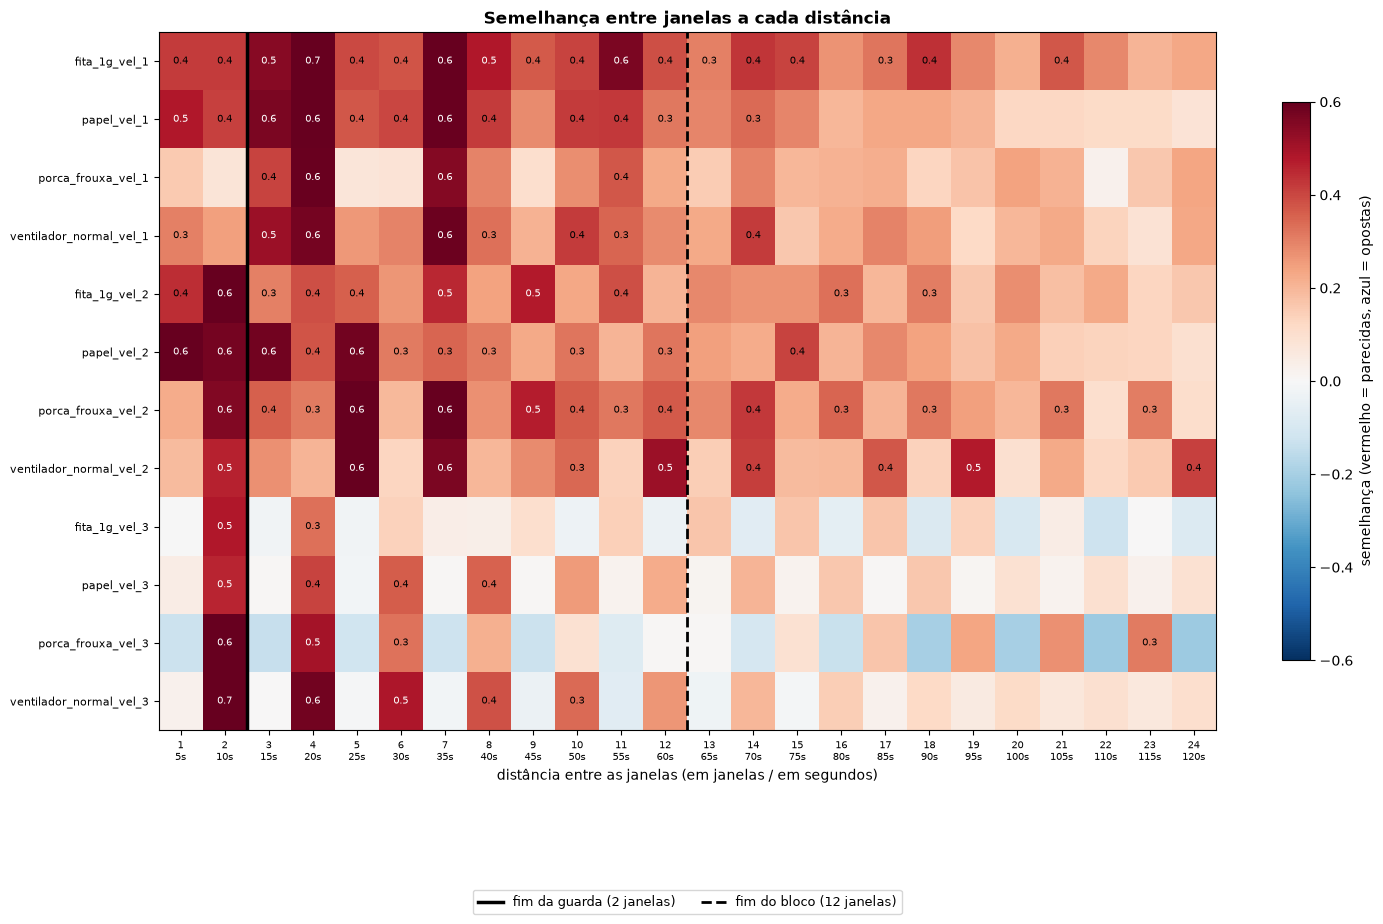

In [10]:
curvas_autocorrelacao = calcular_autocorrelacao_com_sinal(features, COLUNAS_TODAS)
plotar_mapa_autocorrelacao(curvas_autocorrelacao)

### 3.2 — Barras por gravação: o padrão de cada uma

**Como ler:** um painel por gravação, com uma barra para cada distância. **Barra vermelha para cima** = parecidas; **barra azul para baixo** = opostas. A faixa laranja é a **guarda** (essas janelas vizinhas são descartadas) e a linha tracejada é o fim de um **bloco**.

**Os três padrões que dá para reconhecer:**

* **Barras vermelhas que vão diminuindo devagar, sem azul:** deriva lenta (a gravação muda aos poucos do começo ao fim).
* **Vermelho e azul alternando (uma barra sim, outra não):** alternância forte/fraca, o ciclo da oscilação cortado pelas janelas de 5 s.
* **Picos vermelhos isolados em certas distâncias** (por exemplo, a cada 7 janelas): o ciclo voltando à mesma fase.

In [11]:
def plotar_barras_por_base(curvas):
    """Um painel por gravação: barras da semelhança a cada distância, com a guarda e o fim do bloco."""
    bases = ordenar_bases(curvas.columns)
    linhas = int(np.ceil(len(bases) / 2))
    fig, axs = plt.subplots(linhas, 2, figsize=(16, 2.4 * linhas + 1.2), sharex=True, sharey=True, squeeze=False)
    for ax, base in zip(axs.T.ravel(), bases):
        valores = curvas[base]
        ax.bar(valores.index, valores.values, color=np.where(valores.values >= 0, "tab:red", "tab:blue"), width=0.8)
        ax.axvspan(0.5, GUARDA_JANELAS + 0.5, color="orange", alpha=0.25)
        ax.axvline(BLOCO_JANELAS + 0.5, color="black", linestyle="--", linewidth=1)
        ax.axhline(0, color="black", linewidth=0.8)
        ax.set_title(base, fontsize=10, fontweight="bold", loc="left")
        ax.set_ylim(-0.7, 0.7)
    for ax in axs[-1]:
        ax.set_xlabel(f"distância (janelas de {JANELA_S} s)")
    for ax in axs[:, 0]:
        ax.set_ylabel("semelhança")
    fig.legend(handles=[Patch(color="orange", alpha=0.4, label="guarda (descartada)"), Patch(color="tab:red", label="parecidas"),
                        Patch(color="tab:blue", label="opostas (alternância)")], loc="lower center", fontsize=9, ncol=3)
    fig.suptitle("Semelhança entre janelas a cada distância, por gravação", fontsize=12, fontweight="bold")
    plt.tight_layout(rect=[0, 0.04, 1, 0.96])
    plt.show()

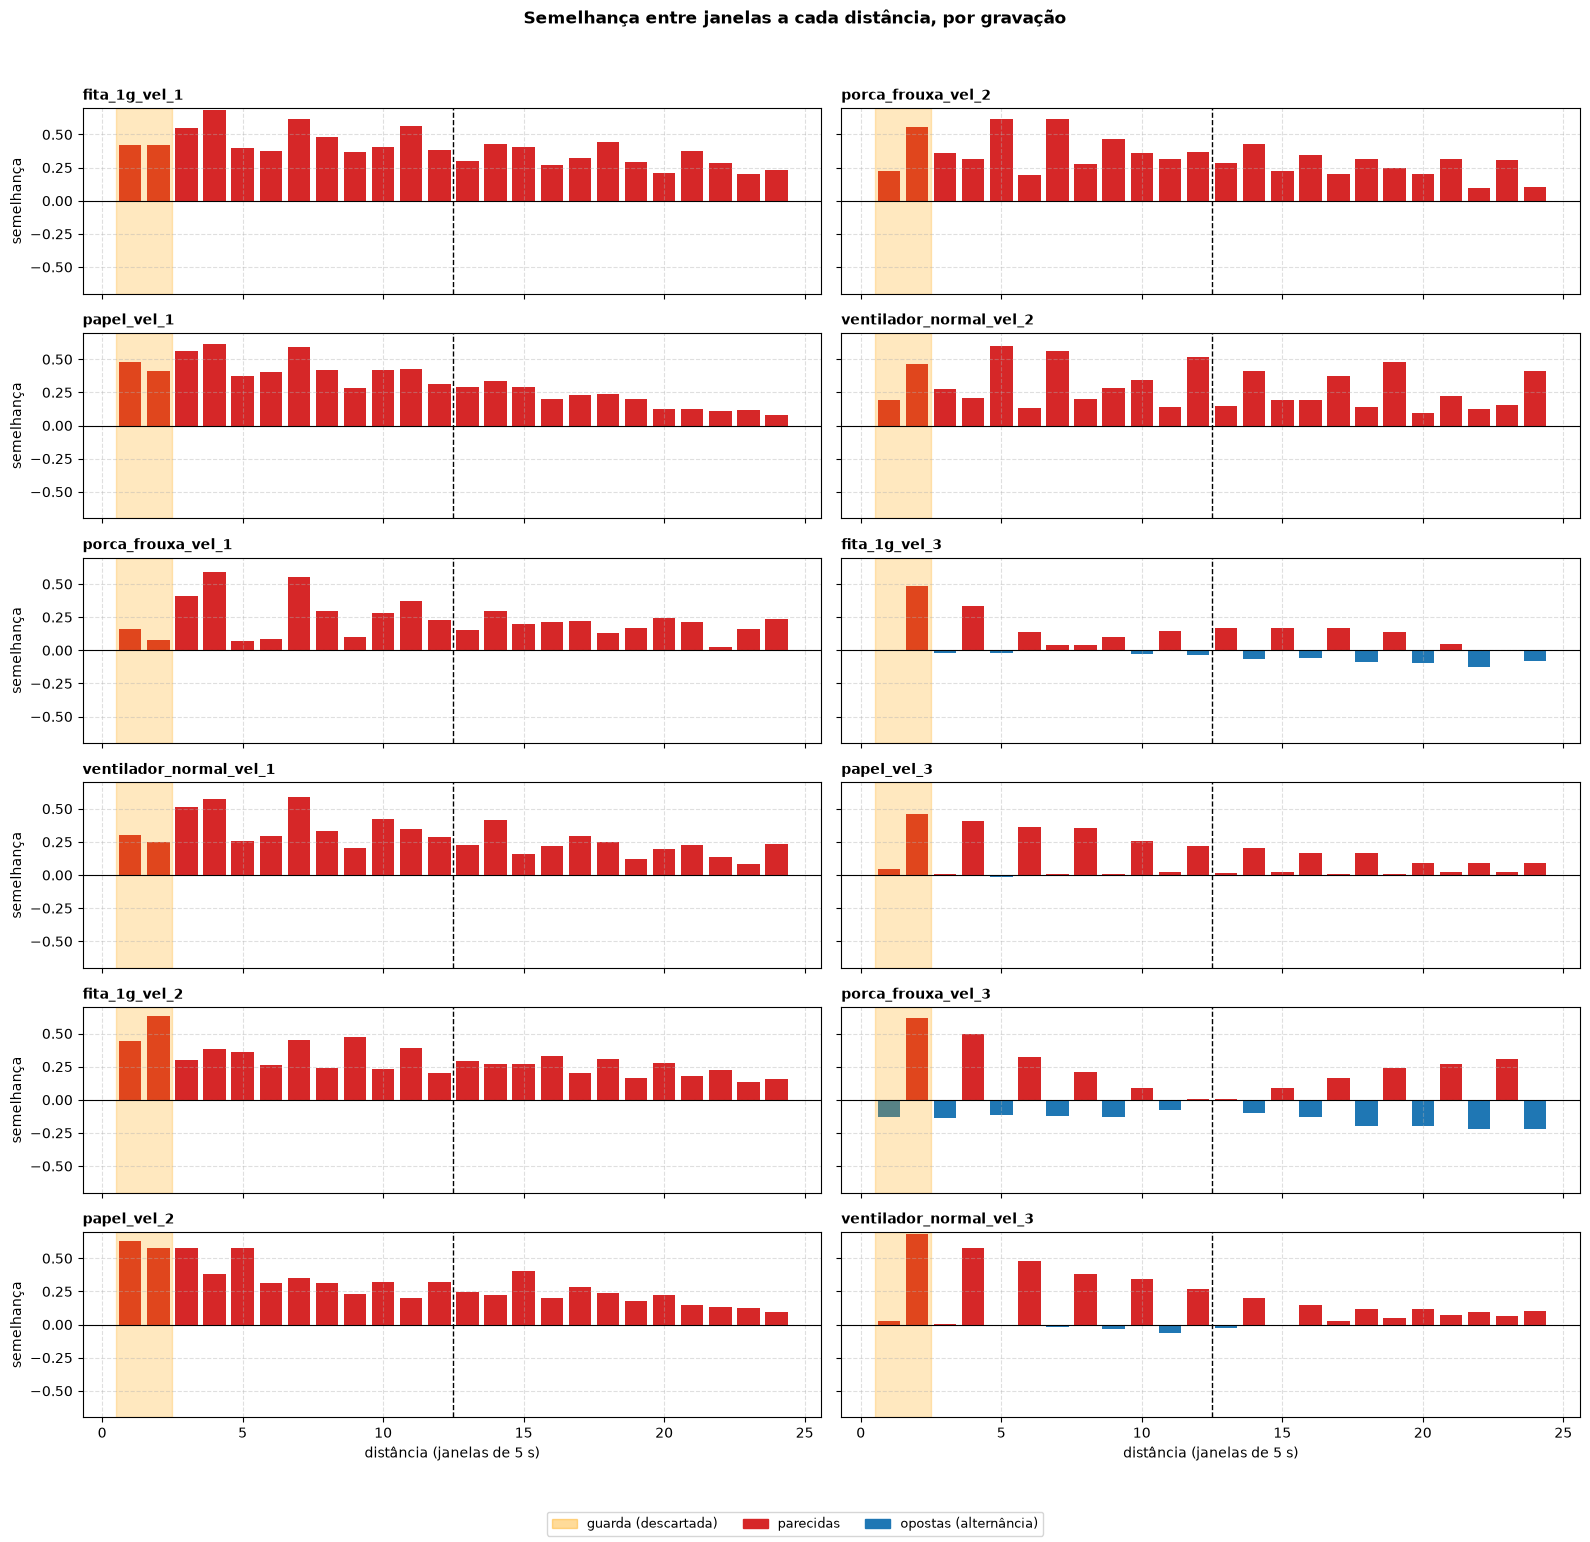

In [12]:
plotar_barras_por_base(curvas_autocorrelacao)

### 3.3 — Matriz de semelhança: cada janela contra cada outra

**O que é:** os dois gráficos anteriores resumem a semelhança por **distância**. Esta figura mostra **todos os pares de janelas** de uma gravação. A célula (linha i, coluna j) diz o quanto a janela i se parece com a janela j, comparando as 109 features (depois do log, padronizadas dentro da gravação).

**Como ler:**

* **A diagonal** é sempre vermelho-escura: cada janela é idêntica a ela mesma.
* **Faixa vermelha larga ao redor da diagonal:** janelas próximas no tempo são parecidas.
* **Dois quadrados grandes** (um no canto superior esquerdo e outro no inferior direito), com azul entre eles: a gravação **muda de comportamento no meio**. O começo parece com o começo, o fim com o fim, mas um não parece com o outro (deriva ou mudança de regime).
* **Listras diagonais paralelas:** o padrão se **repete** a uma distância fixa (o ciclo da oscilação).
* **Xadrez fino:** janelas vizinhas **alternam** (uma forte, outra fraca).
* **As linhas pretas** marcam os blocos de `BLOCO_JANELAS` janelas. Um bloco vira um pequeno quadrado: o que importa é que os quadrados de treino e de teste não "colem" um do outro pela borda, e é para isso que serve a guarda.

In [13]:
def matriz_de_semelhanca(features, base, colunas):
    """Correlação entre os vetores de features de cada par de janelas de uma gravação (log e padronização na gravação)."""
    grupo = features[features["base"] == base].sort_values("janela")
    valores = grupo[colunas].astype(float)
    com_log = [c for c in colunas if c not in COLUNAS_SEM_LOG]
    valores[com_log] = np.log(valores[com_log])
    padronizado = (valores - valores.mean()) / valores.std().replace(0, 1)
    return np.corrcoef(padronizado.to_numpy())


def plotar_matrizes_de_semelhanca(features, colunas, bloco_janelas=BLOCO_JANELAS):
    """Uma matriz janela x janela por gravação, com as fronteiras dos blocos."""
    bases = ordenar_bases(features["base"].unique())
    colunas_fig = 3
    linhas = int(np.ceil(len(bases) / colunas_fig))
    fig, axs = plt.subplots(linhas, colunas_fig, figsize=(6 * colunas_fig, 5.6 * linhas), squeeze=False)
    for ax, base in zip(axs.ravel(), bases):
        matriz = matriz_de_semelhanca(features, base, colunas)
        imagem = ax.imshow(matriz, cmap="RdBu_r", vmin=-1, vmax=1, interpolation="nearest")
        for inicio in range(bloco_janelas, len(matriz), bloco_janelas):
            ax.axhline(inicio - 0.5, color="black", linewidth=0.5)
            ax.axvline(inicio - 0.5, color="black", linewidth=0.5)
        ax.set_title(base, fontsize=11, fontweight="bold")
        ax.set_xlabel("janela")
        ax.set_ylabel("janela")
        ax.grid(False)
    for ax in axs.ravel()[len(bases):]:
        ax.axis("off")
    fig.colorbar(imagem, ax=axs.ravel().tolist(), label="semelhança entre as duas janelas", shrink=0.6)
    fig.suptitle(f"Quanto cada janela se parece com cada outra (linhas pretas = blocos de {bloco_janelas * JANELA_S} s)",
                 fontsize=12, fontweight="bold")
    plt.show()

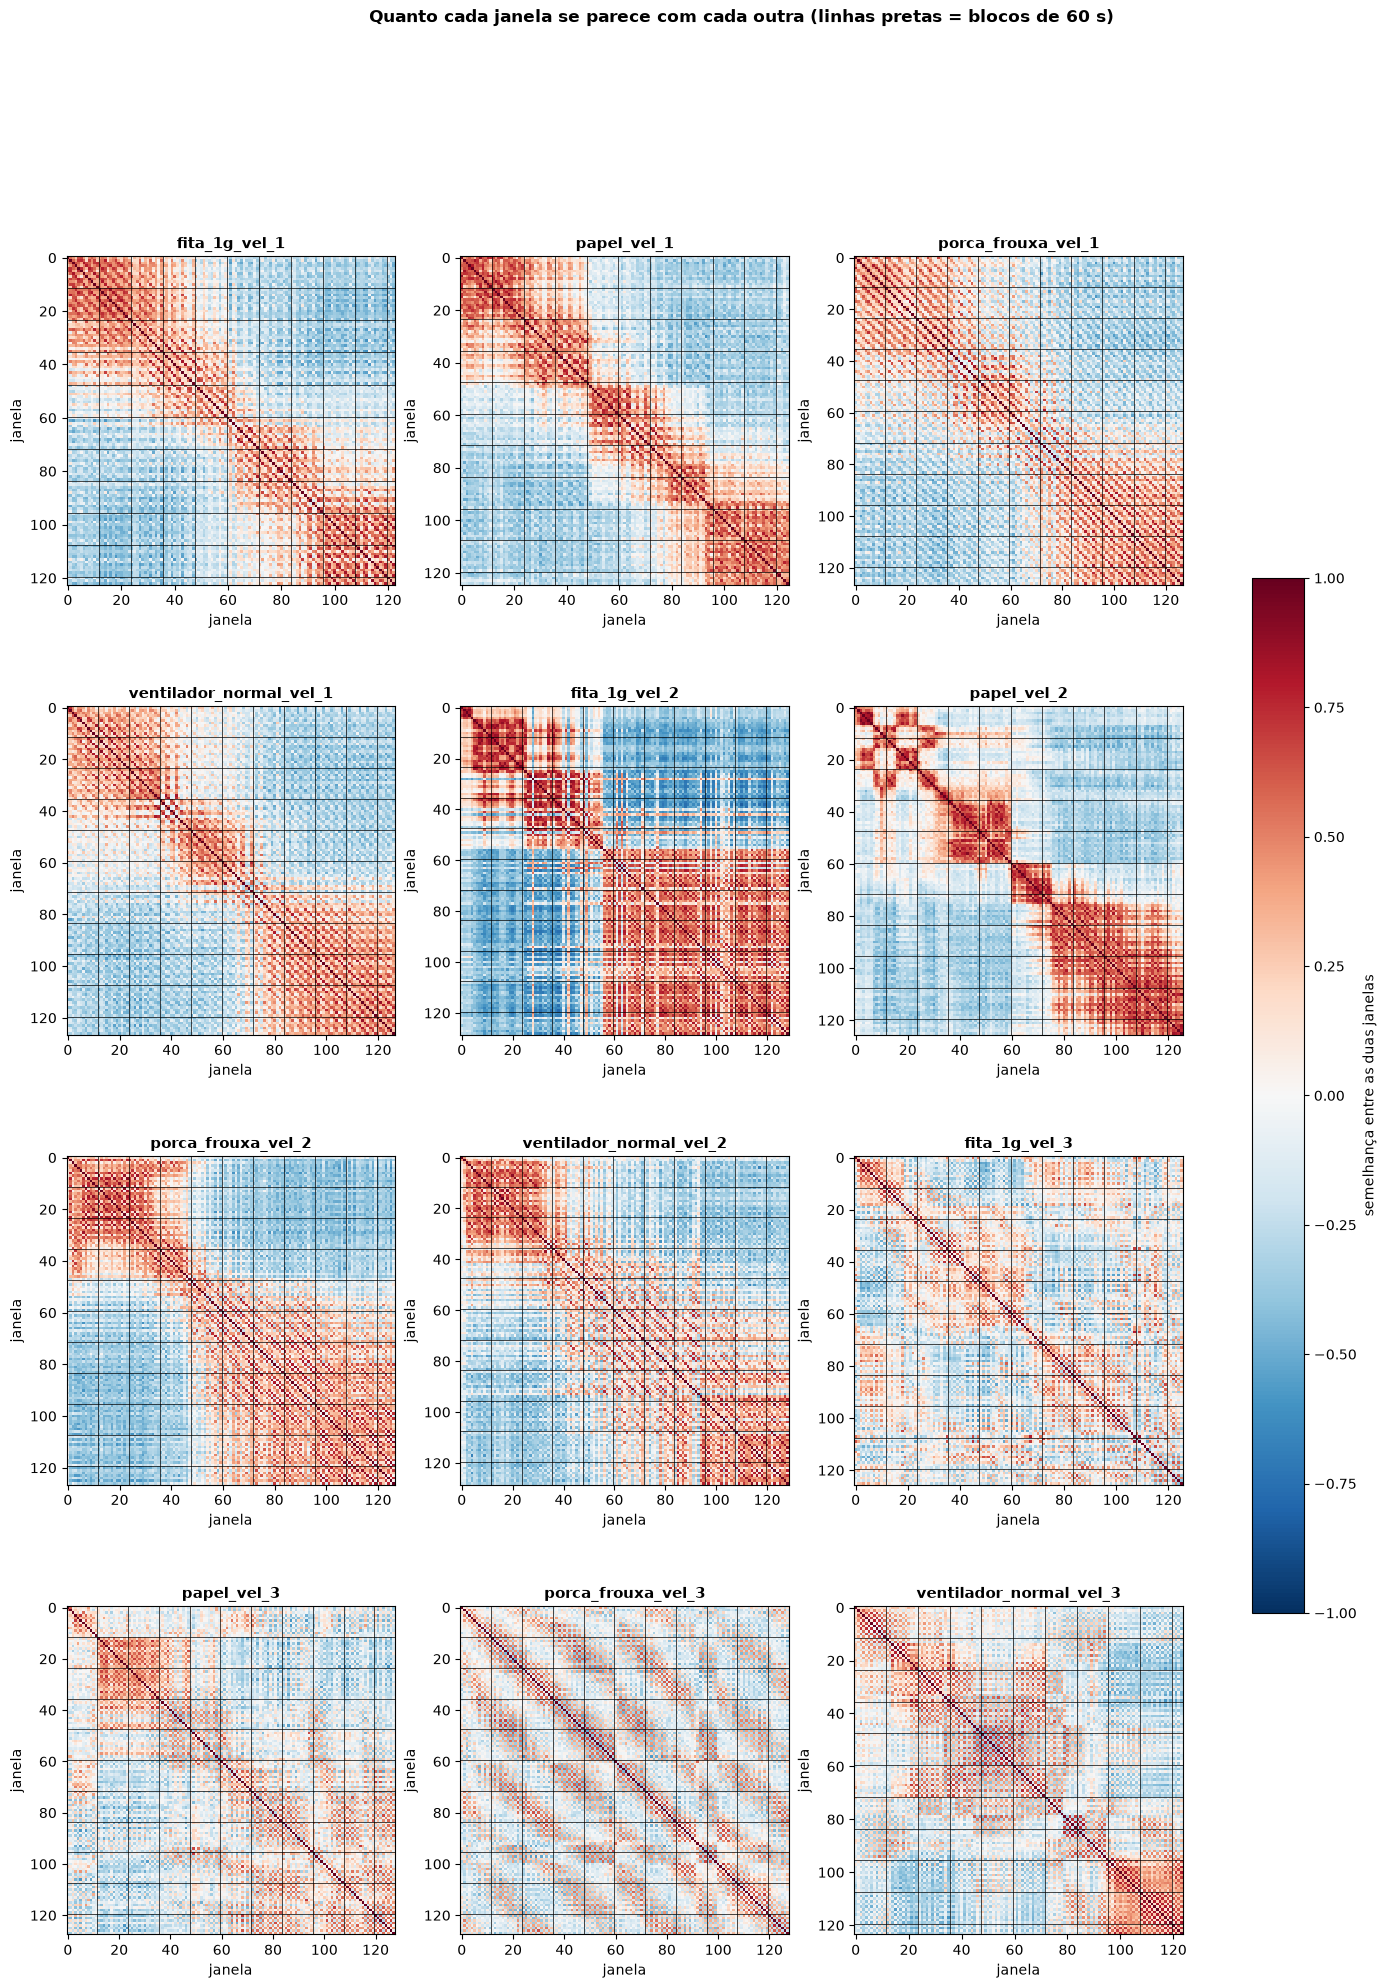

In [14]:
plotar_matrizes_de_semelhanca(features, COLUNAS_TODAS)

### O que as três figuras mostram e por que escolhemos estes valores (dados novos)

**1. O ciclo da oscilação aparece como "picos" de semelhança, e o ritmo depende da velocidade (mapa e barras).**
* **Vel 3:** picos em 2, 4, 6 e 8 janelas (10, 20, 30 e 40 s), com +0,5 a +0,7 no lag 2. O ciclo da Vel 3 dura cerca de 10 s, ou seja, 2 janelas.
* **Vel 2:** picos em 2, 5, 7 e 12 janelas. O ciclo dura cerca de 12 s, ou 2,4 janelas, então os retornos caem "entre" janelas.
* **Vel 1:** picos em 3 a 4 e em 7 janelas (15 a 20 s e 35 s). O ciclo dura cerca de 18 s, ou 3,6 janelas.
* Isso bate com o Notebook 03 (Passo 7.2.1): **o ciclo dura cerca de 225 voltas da hélice**, por isso é mais lento na Vel 1. **Esse retorno não é vazamento:** é a máquina repetindo o próprio padrão, e vai acontecer igual em dados futuros.

**2. O aquecimento aparece como quadrados grandes (matriz de semelhança).**
* As gravações das **Vel 1 e 2** formam dois ou três quadrados grandes: o começo parece com o começo, o fim com o fim.
* A **fita V2** e o **papel V2** têm uma mudança forte nos primeiros cerca de 4 minutos.
* A **Vel 3** quase não tem quadrados, só as **listras diagonais** do ciclo. A porca V3 é o exemplo mais limpo.
* **Nenhuma guarda resolve o aquecimento, porque ele dura a gravação inteira.** O que resolve é o teste trancado **cobrir o começo, o meio e o fim** (Passo 4) e o teste cronológico (Passo 12.2) medir quanto o modelo depende disso.

**3. Valores mantidos:**
* **Guarda de 2 janelas (10 s):** cobre a vizinhança imediata.
* **Blocos de 12 janelas (60 s):** cada bloco tem de 3 a 6 ciclos inteiros da oscilação, conforme a velocidade. Assim, nenhum bloco fica preso a uma fase do ciclo.

## Passo 4 — Cortar em blocos e separar o teste trancado

**O que o código faz:**

1. **Corta cada gravação em blocos** de `BLOCO_JANELAS` janelas seguidas (12 janelas = 60 s). Se sobrar um pedaço no fim menor que meio bloco, ele é juntado ao bloco anterior.
2. **Sorteia os blocos do teste trancado em cada gravação.** Com `TRANCADO_UM_POR_TERCO = True`, os blocos da gravação são divididos em `BLOCOS_TRANCADOS_POR_BASE` partes seguidas (3 partes = começo, meio e fim) e **um bloco é sorteado em cada parte**. O sorteio é por gravação, para que **todas as classes** (velocidade × condição) apareçam no teste trancado na mesma proporção. A semente é fixa, então o sorteio é sempre o mesmo.
3. **Marca a guarda:** as `GUARDA_JANELAS` janelas de cada lado de um bloco trancado são descartadas. Elas não entram nem no treino nem no teste.
4. **O resto é o conjunto de desenvolvimento**, onde todos os modelos são treinados e comparados (Passos 5 a 12).

**Por que um teste trancado, se já existe validação cruzada?** Durante o notebook comparamos modelos, conjuntos de features e arquiteturas na validação cruzada, e **escolhemos** os melhores. Cada escolha usa a validação para decidir, e por isso ela fica um pouco "otimista": escolhemos justamente o que foi melhor **nela**. O teste trancado **não participa de nenhuma escolha**. É como a prova final: os simulados (validação) servem para estudar; a prova (trancado) mede o resultado.

**Por que um bloco em cada terço?** Nos dados novos, o começo e o fim de cada gravação são diferentes por causa do aquecimento (Notebooks 03 e 04). Um sorteio livre poderia pôr os dois blocos trancados no fim de uma gravação, e o teste mediria só "motor quente". Com um bloco em cada terço, o trancado cobre **motor frio, morno e quente** em todas as classes. O efeito do tempo em si (treinar só no começo e testar só no fim) tem o seu próprio teste no Passo 12.2.

**O que vem a seguir:** uma tabela com quantas janelas de cada classe foram para cada papel, a lista dos blocos sorteados (com o trecho de tempo de cada um) e o mapa dos blocos (4.1).

In [15]:
def numerar_blocos(features, bloco_janelas=BLOCO_JANELAS):
    """Número do bloco de cada janela, dentro da sua gravação. Sobra menor que meio bloco vai para o bloco anterior."""
    blocos = features["janela"] // bloco_janelas
    for base, grupo in features.groupby("base"):
        ultimo = blocos[grupo.index].max()
        tamanho_ultimo = (blocos[grupo.index] == ultimo).sum()
        if ultimo > 0 and tamanho_ultimo < bloco_janelas / 2:
            blocos[grupo.index[blocos[grupo.index] == ultimo]] = ultimo - 1
    return blocos


def marcar_guarda(features, em_teste, guarda=GUARDA_JANELAS):
    """True nas janelas que NÃO estão em teste mas ficam a até 'guarda' janelas de uma janela de teste da mesma gravação."""
    perto = pd.Series(False, index=features.index)
    for base, grupo in features.groupby("base"):
        janelas_teste = grupo.loc[em_teste[grupo.index], "janela"].to_numpy()
        if len(janelas_teste) == 0:
            continue
        distancia = np.abs(grupo["janela"].to_numpy()[:, None] - janelas_teste[None, :]).min(axis=1)
        perto[grupo.index] = (distancia <= guarda) & ~em_teste[grupo.index].to_numpy()
    return perto


def sortear_teste_trancado(features, blocos_por_base=BLOCOS_TRANCADOS_POR_BASE, semente=SEMENTE, um_por_terco=TRANCADO_UM_POR_TERCO):
    """Sorteia, em cada gravação, os blocos do teste trancado. Devolve o papel de cada janela.

    um_por_terco=True: os blocos da gravação são divididos em 'blocos_por_base' partes seguidas
    (com 3: começo, meio e fim) e um bloco é sorteado em cada parte.
    """
    gerador = np.random.default_rng(semente)
    trancado = pd.Series(False, index=features.index)
    for base, grupo in features.groupby("base"):
        blocos_da_base = np.sort(grupo["bloco"].unique())
        if um_por_terco:
            escolhidos = [gerador.choice(parte) for parte in np.array_split(blocos_da_base, blocos_por_base)]
        else:
            escolhidos = gerador.choice(blocos_da_base, size=min(blocos_por_base, len(blocos_da_base) - 1), replace=False)
        trancado[grupo.index] = grupo["bloco"].isin(escolhidos).to_numpy()
    guarda = marcar_guarda(features, trancado)
    return pd.Series(np.select([trancado, guarda], ["trancado", "guarda"], "desenvolvimento"), index=features.index)

In [16]:
features["bloco"] = numerar_blocos(features)
features["papel"] = sortear_teste_trancado(features)
features["nome_classe"] = "Vel " + features["velocidade"].astype(str) + " - " + features["rotulo_condicao"]

tabela_papeis = pd.crosstab(features["nome_classe"], features["papel"], margins=True, margins_name="Total")
tabela_papeis = tabela_papeis[["desenvolvimento", "trancado", "guarda", "Total"]]
display(tabela_papeis)

blocos_trancados = features[features["papel"] == "trancado"].groupby("nome_classe")["bloco"].unique().apply(lambda b: sorted(int(x) for x in b))
print("Blocos sorteados para o teste trancado (número do bloco dentro da gravação):")
for classe, blocos_da_classe in blocos_trancados.items():
    inicio = [f"{b * BLOCO_JANELAS * JANELA_S}–{(b + 1) * BLOCO_JANELAS * JANELA_S} s" for b in blocos_da_classe]
    print(f"  {classe}: blocos {list(blocos_da_classe)} ({', '.join(inicio)})")

papel,desenvolvimento,trancado,guarda,Total
nome_classe,,,,
Vel 1 - fita_1g,77,36,10,123
Vel 1 - normal,79,36,12,127
Vel 1 - papel,76,41,8,125
Vel 1 - porca_frouxa,79,36,12,127
Vel 2 - fita_1g,86,33,10,129
Vel 2 - normal,81,36,12,129
Vel 2 - papel,86,30,10,126
Vel 2 - porca_frouxa,86,31,10,127
Vel 3 - fita_1g,80,36,10,126


Blocos sorteados para o teste trancado (número do bloco dentro da gravação):
  Vel 1 - fita_1g: blocos [0, 6, 8] (0–60 s, 360–420 s, 480–540 s)
  Vel 1 - normal: blocos [3, 6, 9] (180–240 s, 360–420 s, 540–600 s)
  Vel 1 - papel: blocos [0, 5, 9] (0–60 s, 300–360 s, 540–600 s)
  Vel 1 - porca_frouxa: blocos [3, 5, 9] (180–240 s, 300–360 s, 540–600 s)
  Vel 2 - fita_1g: blocos [1, 5, 10] (60–120 s, 300–360 s, 600–660 s)
  Vel 2 - normal: blocos [1, 4, 8] (60–120 s, 240–300 s, 480–540 s)
  Vel 2 - papel: blocos [2, 7, 10] (120–180 s, 420–480 s, 600–660 s)
  Vel 2 - porca_frouxa: blocos [1, 4, 10] (60–120 s, 240–300 s, 600–660 s)
  Vel 3 - fita_1g: blocos [0, 6, 8] (0–60 s, 360–420 s, 480–540 s)
  Vel 3 - normal: blocos [2, 6, 7] (120–180 s, 360–420 s, 420–480 s)
  Vel 3 - papel: blocos [3, 6, 8] (180–240 s, 360–420 s, 480–540 s)
  Vel 3 - porca_frouxa: blocos [3, 6, 9] (180–240 s, 360–420 s, 540–600 s)


### 4.1 — Mapa dos blocos

**Como ler:** cada linha é uma classe (uma gravação), e cada quadradinho é uma janela de 5 s, posicionada no **tempo dentro da gravação** (em segundos). A cor diz para onde a janela foi:

* **azul (desenvolvimento):** usada para treinar e comparar modelos (Passos 5 a 11);
* **laranja (teste trancado):** guardada até o Passo 12;
* **cinza (guarda):** descartada, é o "fosso" que separa o teste trancado do resto.

As linhas verticais finas marcam a fronteira de cada bloco de 60 s.

**Diferença em relação ao notebook antigo:** lá, a guarda era colocada **entre todos os blocos**, o que descartava 108 janelas. Aqui ela só aparece **onde treino e teste se encostam**: em volta dos blocos trancados (este mapa) e em volta dos blocos de validação de cada rodada (Passo 5). A proteção é a mesma e perdemos menos dados.

In [17]:
CORES_PAPEL = {"desenvolvimento": "tab:blue", "trancado": "tab:orange", "guarda": "lightgray"}


def plotar_mapa_de_blocos(features, papeis, titulo, cores=CORES_PAPEL, ax=None):
    """Uma linha por classe; cada janela é um quadrado no seu instante dentro da gravação, colorido pelo papel."""
    papeis = pd.Series(np.asarray(papeis), index=features.index)
    classes = sorted(features["nome_classe"].unique(), key=lambda c: (c.split(" - ")[0], c.split(" - ")[1] != NOME_NORMAL), reverse=True)
    criou = ax is None
    if criou:
        fig, ax = plt.subplots(figsize=(15, 0.65 * len(classes) + 1.6))
    for papel, cor in cores.items():
        sel = (papeis == papel).to_numpy()
        y = [classes.index(c) for c in features.loc[sel, "nome_classe"]]
        ax.scatter(features.loc[sel, "janela"] * JANELA_S, y, marker="s", s=22, color=cor, label=papel)
    for i, classe in enumerate(classes):
        grupo = features[features["nome_classe"] == classe]
        for inicio in grupo.groupby("bloco")["janela"].min().to_numpy()[1:]:
            ax.plot([inicio * JANELA_S - JANELA_S / 2] * 2, [i - 0.3, i + 0.3], color="black", linewidth=0.6)
    ax.set_yticks(range(len(classes)))
    ax.set_yticklabels(classes, fontsize=9)
    ax.set_ylim(-0.6, len(classes) - 0.4)
    ax.set_xlabel("tempo dentro da gravação (segundos)")
    ax.set_title(titulo, fontsize=11, fontweight="bold")
    ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.18 if criou else -0.25), ncol=len(cores), fontsize=9, markerscale=1.3)
    if criou:
        plt.tight_layout()
        plt.show()

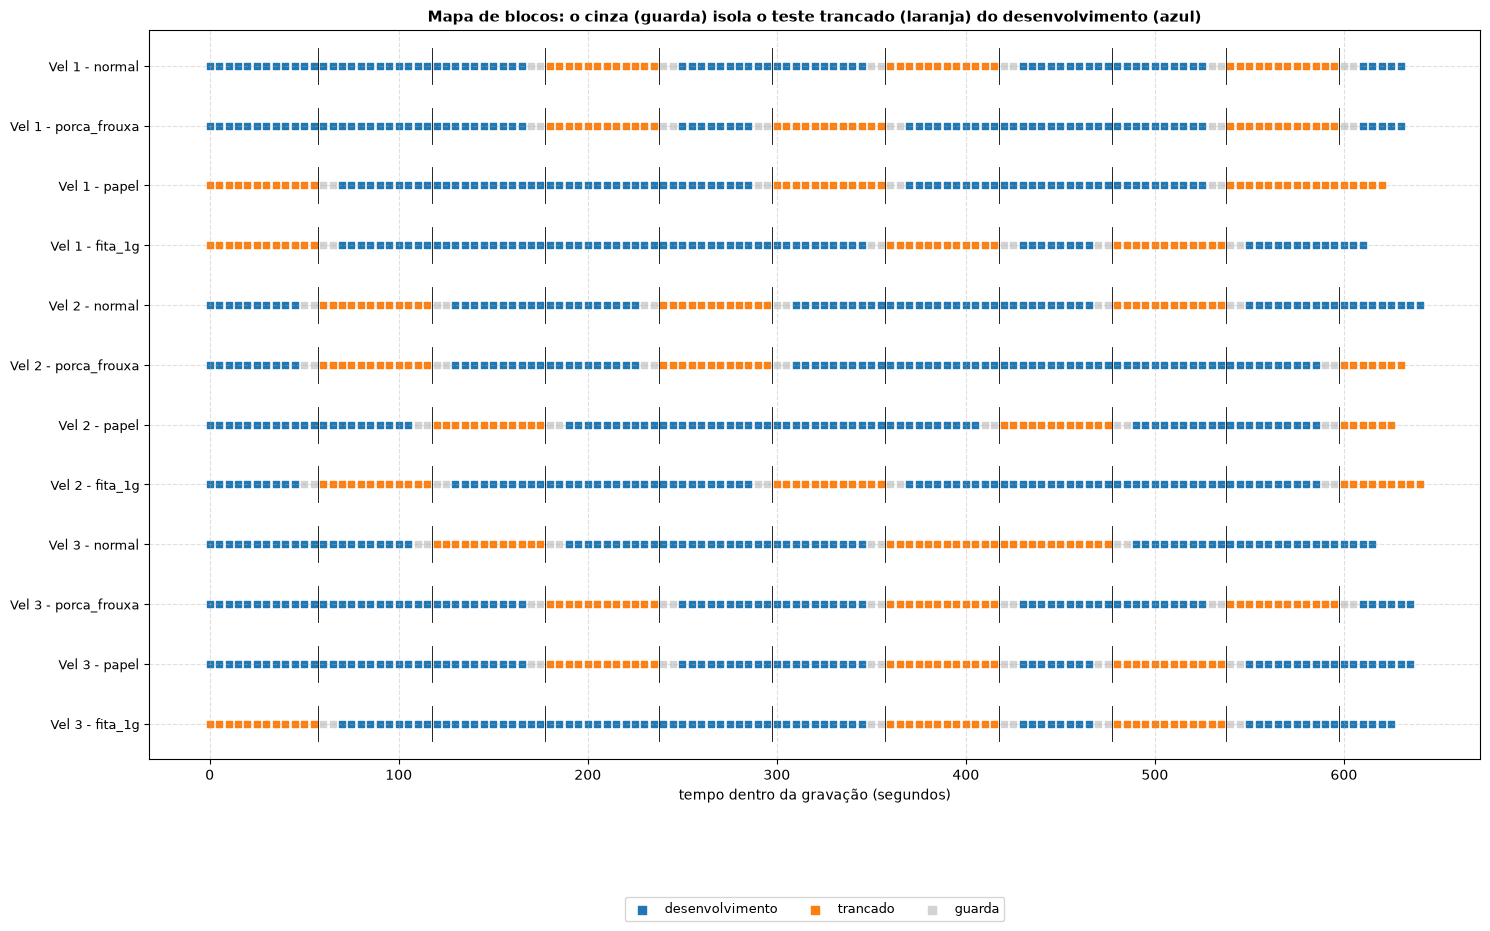

In [18]:
plotar_mapa_de_blocos(features, features["papel"], "Mapa de blocos: o cinza (guarda) isola o teste trancado (laranja) do desenvolvimento (azul)")

### Como ficou a divisão (dados novos)

* **Cada gravação virou 10 ou 11 blocos de 60 s.** Em cada uma, um bloco foi sorteado no começo, um no meio e um no fim.
* **Total:** 970 janelas de desenvolvimento, **423 no teste trancado (28%)** e 126 descartadas na guarda. O trancado ficou maior que nos dados antigos (22%) por causa do terceiro bloco por gravação.
* **O começo de verdade (bloco 0, primeiro minuto) caiu no trancado em 3 gravações:** fita V1, papel V1 e fita V3. Isso é bom: o trancado testa também o motor recém-ligado.
* **Todas as 12 classes estão no trancado com peso parecido** (30 a 41 janelas cada).

## Passo 5 — Validação cruzada por blocos: como comparar modelos sem tocar no trancado

**O que é:** dividimos os blocos do conjunto de desenvolvimento em `N_FOLDS` grupos (folds). Em cada rodada, **um fold é a validação** e os outros são o treino. Repetimos até que cada fold tenha sido validação uma vez. Assim, **toda janela de desenvolvimento é prevista uma vez por um modelo que não a viu**, e juntamos essas previsões numa única matriz de confusão.

**Três regras para ser honesto:**

1. **Blocos inteiros:** um bloco nunca fica dividido entre treino e validação.
2. **Estratificado:** cada fold recebe blocos de todas as 12 classes (velocidade × condição), para não haver um fold sem nenhuma porca da Vel 2, por exemplo (`StratifiedGroupKFold`).
3. **Guarda dentro de cada rodada:** as `GUARDA_JANELAS` janelas vizinhas aos blocos de validação são retiradas do **treino daquela rodada**.

**Como ler a figura:** um painel por rodada, no mesmo formato do mapa do Passo 4. Em cada um: **verde** = validação da rodada, **azul** = treino da rodada, **cinza** = guarda (as vizinhas da validação, retiradas do treino daquela rodada, mais a guarda do trancado) e **bege** = teste trancado, que não aparece em nenhuma rodada. Repare que **cada bloco fica verde em exatamente uma rodada**.

In [19]:
def montar_folds(dev, n_folds=N_FOLDS, semente=SEMENTE):
    """Folds por blocos, estratificados pela classe, com guarda retirada do treino. Índices referem-se a 'dev'."""
    grupos = dev["base"] + "|" + dev["bloco"].astype(str)
    divisor = StratifiedGroupKFold(n_splits=n_folds, shuffle=True, random_state=semente)
    folds = []
    for treino, validacao in divisor.split(dev, dev["rotulo_classe"], groups=grupos):
        em_validacao = pd.Series(False, index=dev.index)
        em_validacao.iloc[validacao] = True
        guarda = marcar_guarda(dev, em_validacao)
        treino_limpo = np.where(~em_validacao.to_numpy() & ~guarda.to_numpy())[0]
        folds.append((treino_limpo, validacao, np.where(guarda.to_numpy())[0]))
    return folds

In [20]:
dev = features[features["papel"] == "desenvolvimento"].copy()
trancado = features[features["papel"] == "trancado"].copy()
folds = montar_folds(dev)

for k, (treino, validacao, guarda) in enumerate(folds, start=1):
    classes_na_validacao = dev.iloc[validacao]["rotulo_classe"].nunique()
    print(f"Rodada {k}: treino {len(treino)} janelas | validação {len(validacao)} | guarda retirada {len(guarda)} | "
          f"classes na validação: {classes_na_validacao} de {len(ORDEM_CLASSES)}")

Rodada 1: treino 736 janelas | validação 194 | guarda retirada 40 | classes na validação: 12 de 12
Rodada 2: treino 740 janelas | validação 184 | guarda retirada 46 | classes na validação: 12 de 12
Rodada 3: treino 739 janelas | validação 199 | guarda retirada 32 | classes na validação: 12 de 12
Rodada 4: treino 734 janelas | validação 194 | guarda retirada 42 | classes na validação: 12 de 12
Rodada 5: treino 731 janelas | validação 199 | guarda retirada 40 | classes na validação: 12 de 12


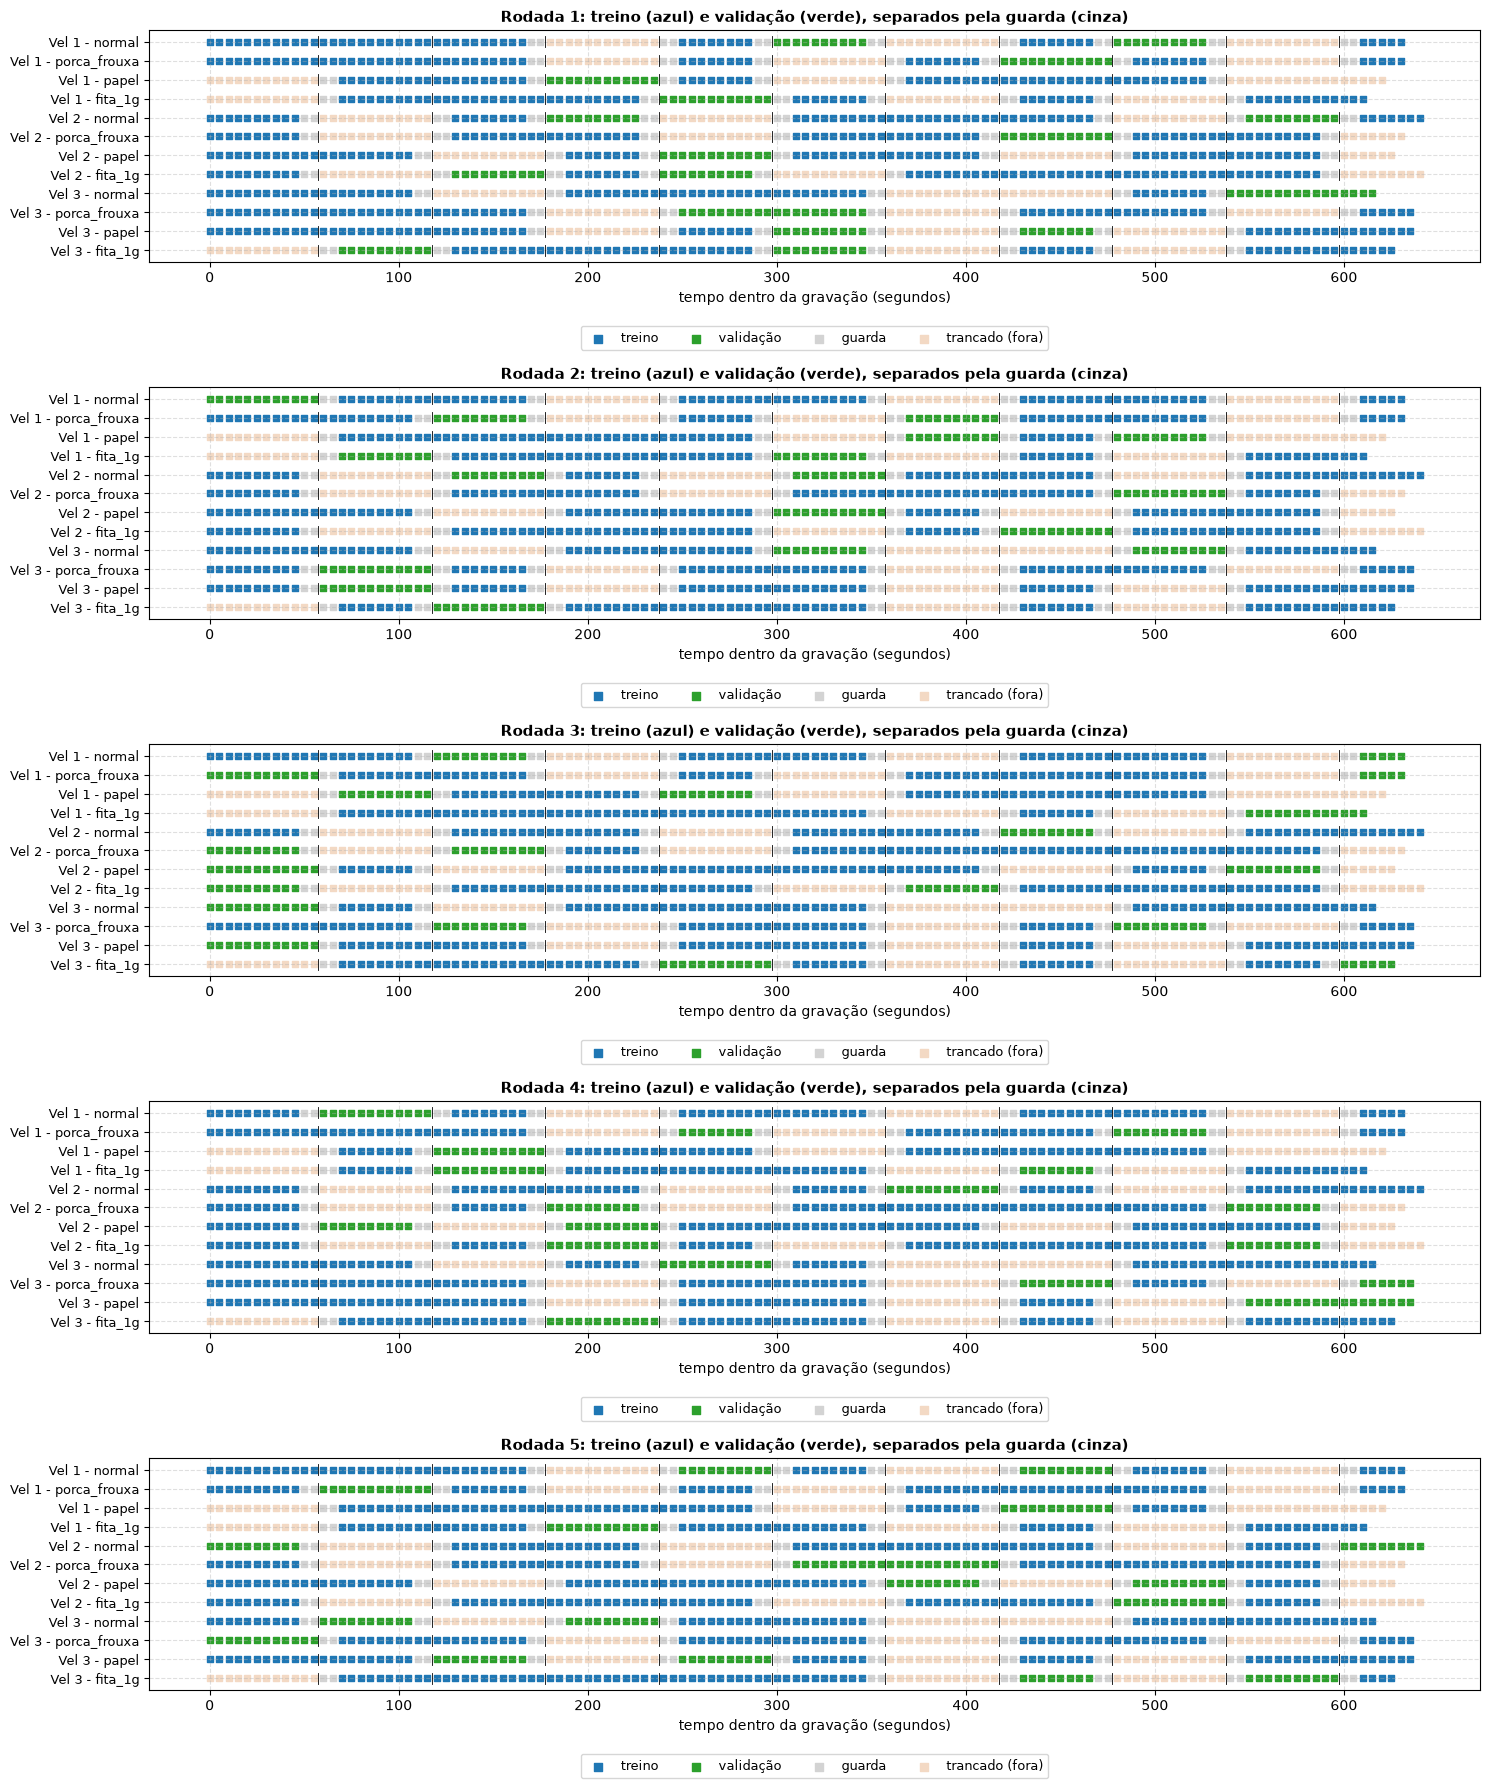

In [21]:
CORES_RODADA = {"treino": "tab:blue", "validação": "tab:green", "guarda": "lightgray", "trancado (fora)": "#f3d9c4"}
fig, axs = plt.subplots(len(folds), 1, figsize=(15, 3.6 * len(folds)))
for k, (ax, (treino, validacao, guarda)) in enumerate(zip(np.atleast_1d(axs), folds), start=1):
    papeis = np.full(len(features), "trancado (fora)", dtype=object)
    papeis[features.index.get_indexer(dev.index[treino])] = "treino"
    papeis[features.index.get_indexer(dev.index[validacao])] = "validação"
    papeis[features.index.get_indexer(dev.index[guarda])] = "guarda"
    papeis[(features["papel"] == "guarda").to_numpy()] = "guarda"
    plotar_mapa_de_blocos(features, papeis, f"Rodada {k}: treino (azul) e validação (verde), separados pela guarda (cinza)",
                          cores=CORES_RODADA, ax=ax)
plt.tight_layout()
plt.show()

## Passo 6 — Pipeline: log → scaler → modelo, com o scaler ajustado só no treino

**O vazamento que o Notebook 04 tinha (e que aqui não pode ter):** lá, o scaler calculava média e desvio usando **todas** as janelas, inclusive as que depois eram avaliadas. Se a média for calculada com janelas de teste, o modelo recebe uma "dica" sobre elas. Aqui, **média e desvio vêm só das janelas de treino de cada rodada** e são aplicados, sem recalcular, às janelas de validação.

**Como garantimos isso:** com um `Pipeline` do scikit-learn, uma "esteira" com três etapas:

1. **Log** nas features (menos a curtose), como nos Notebooks 03 e 04. O log não aprende nada, é a mesma conta para todo mundo.
2. **StandardScaler**, que aprende média e desvio **no `fit` (treino)** e só aplica no `predict` (validação/teste).
3. **O modelo.**

Quando chamamos `pipeline.fit(treino)`, as três etapas aprendem só com o treino. Quando chamamos `pipeline.predict(teste)`, o teste passa pela esteira já ajustada. **Não há como o teste vazar para o ajuste.**

### As três arquiteturas da Tarefa D (condição: normal, fita, papel ou porca)

| Arquitetura | Como funciona | Corresponde a |
| --- | --- | --- |
| **1. Classificador único** | Um modelo só recebe a janela e escolhe uma das 4 condições, sem saber a velocidade. | O mais simples possível |
| **2. Por velocidade** | **Etapa 1:** um modelo prevê a velocidade (Tarefa A). **Etapa 2:** um classificador de condição **daquela velocidade**, treinado só com janelas dela. O scaler da etapa 2 é **local**, como o do Notebook 04, mas ajustado só no treino. | "Primeiro descubra a velocidade" |
| **3. Detector → tipo** | **Etapa 1 (detector):** normal ou anomalia? (Tarefa B). **Etapa 2 (diagnóstico):** só as janelas acusadas passam por um classificador treinado **só com janelas de falha**, que diz qual falha é (Tarefa C). | **"Um modelo chama o outro"**, a arquitetura planejada para a API |

Cada etapa é um pipeline completo (log → scaler → modelo), então cada etapa tem o seu próprio scaler, ajustado só com as janelas de treino que ela recebe.

**Como um erro se propaga:**

* **Na arquitetura 2**, se a etapa 1 errar a velocidade, a janela vai para o classificador da velocidade errada.
* **Na arquitetura 3**, se o detector deixar passar uma falha, ela vira "normal" e o diagnóstico nem chega a vê-la. Se o detector acusar uma janela normal (falso alarme), o diagnóstico **é obrigado a dizer uma falha**, porque só conhece falhas.

O Passo 11 mostra onde cada arquitetura erra.

In [22]:
def criar_pipeline(modelo, colunas):
    """Esteira log -> StandardScaler -> modelo. Log em todas as colunas menos COLUNAS_SEM_LOG."""
    com_log = [c for c in colunas if c not in COLUNAS_SEM_LOG]
    sem_log = [c for c in colunas if c in COLUNAS_SEM_LOG]
    preparo = ColumnTransformer([("log", FunctionTransformer(np.log), com_log), ("sem_log", "passthrough", sem_log)])
    return Pipeline([("log", preparo), ("scaler", StandardScaler()), ("modelo", modelo)])


def separar_rotulo(y):
    """Separa rótulos no formato '<condição> <velocidade>' (ex.: 'papel V2') em (condições, velocidades)."""
    y = pd.Series(np.asarray(y))
    return y.str.rsplit(" ", n=1).str[0].to_numpy(), y.str.rsplit(" ", n=1).str[1].to_numpy()


class ClassificadorUnico(BaseEstimator, ClassifierMixin):
    """Arquitetura 1: um modelo só, que escolhe a condição (normal, fita, papel, porca) sem saber a velocidade."""
    def __init__(self, pipeline):
        self.pipeline = pipeline

    def fit(self, X, y):
        condicao, _ = separar_rotulo(y)
        self.modelo_ = clone(self.pipeline).fit(X, condicao)
        return self

    def predict(self, X):
        return self.modelo_.predict(X)


class PorVelocidade(BaseEstimator, ClassifierMixin):
    """Arquitetura 2: a etapa 1 prevê a velocidade; a etapa 2 é um classificador de condição treinado só com
    as janelas daquela velocidade (por isso o seu scaler é local, como o do Notebook 04, mas ajustado só no treino)."""
    def __init__(self, pipeline_velocidade, pipeline_condicao):
        self.pipeline_velocidade = pipeline_velocidade
        self.pipeline_condicao = pipeline_condicao

    def fit(self, X, y):
        condicao, velocidade = separar_rotulo(y)
        self.etapa1_ = clone(self.pipeline_velocidade).fit(X, velocidade)
        self.etapa2_ = {}
        for v in np.unique(velocidade):
            sel = velocidade == v
            if len(np.unique(condicao[sel])) == 1:
                self.etapa2_[v] = condicao[sel][0]
            else:
                self.etapa2_[v] = clone(self.pipeline_condicao).fit(X[sel], condicao[sel])
        return self

    def predict(self, X):
        velocidade = self.etapa1_.predict(X)
        condicao = np.empty(len(X), dtype=object)
        for v in np.unique(velocidade):
            sel = velocidade == v
            etapa2 = self.etapa2_.get(v)
            condicao[sel] = etapa2 if isinstance(etapa2, str) else etapa2.predict(X[sel])
        return condicao


class DetectorDepoisTipo(BaseEstimator, ClassifierMixin):
    """Arquitetura 3 ("um modelo chama o outro"): o detector decide normal ou anomalia; só as janelas acusadas
    vão para o diagnóstico, treinado só com janelas de falha, que diz qual é a falha."""
    def __init__(self, pipeline_detector, pipeline_tipo):
        self.pipeline_detector = pipeline_detector
        self.pipeline_tipo = pipeline_tipo

    def fit(self, X, y):
        condicao, _ = separar_rotulo(y)
        binario = np.where(condicao == NOME_NORMAL, NOME_NORMAL, NOME_ANOMALIA)
        self.detector_ = clone(self.pipeline_detector).fit(X, binario)
        com_falha = condicao != NOME_NORMAL
        self.tipo_ = clone(self.pipeline_tipo).fit(X[com_falha], condicao[com_falha])
        return self

    def predict(self, X):
        acusadas = self.detector_.predict(X) == NOME_ANOMALIA
        condicao = np.full(len(X), NOME_NORMAL, dtype=object)
        if acusadas.any():
            condicao[acusadas] = self.tipo_.predict(X[acusadas])
        return condicao


ARQUITETURAS = {
    "classificador único": lambda fabrica, colunas: ClassificadorUnico(criar_pipeline(fabrica(), colunas)),
    "detector → tipo": lambda fabrica, colunas: DetectorDepoisTipo(criar_pipeline(fabrica(), colunas), criar_pipeline(fabrica(), colunas)),
    "por velocidade": lambda fabrica, colunas: PorVelocidade(criar_pipeline(fabrica(), colunas), criar_pipeline(fabrica(), colunas)),
}

## Passo 7 — Métricas, modelos e a regra de escolha

### A acurácia balanceada

Além das métricas do Notebook 04 (matriz de confusão, recall por classe, falso alarme), usamos a **acurácia balanceada**: a **média dos recalls de todas as classes**.

* **Exemplo:** 4 classes com recall de 100%, 100%, 100% e 40% → acurácia balanceada = (100 + 100 + 100 + 40) / 4 = 85%.
* **Por que usar:** a acurácia comum dá mais peso às classes com mais janelas. Nos dados novos há **3 janelas com falha para cada normal**. Na Tarefa B, um modelo que diz sempre "anomalia" tem acurácia comum de cerca de 75%, mas acurácia balanceada de **50%**. A balanceada dá o **mesmo peso a cada classe**, então uma classe mal acertada sempre puxa a nota para baixo.

Também guardamos o **pior recall entre as classes**: o recall da classe mais mal acertada. É ele que mostra se uma falha (como a porca V2) está sendo sacrificada em troca da média.

### Os modelos

**Referências ("modelos burros"), para saber o quanto o problema é fácil:**

| Modelo | Como funciona | Para que serve |
| --- | --- | --- |
| **Classe mais comum** | Responde sempre a classe com mais janelas no treino | O piso: qualquer modelo útil tem que passar dele com folga |
| **Stump (1 pergunta)** | Uma árvore de decisão com uma pergunta só, por exemplo "`std_y` > 1,2?" | Se 1 pergunta já acerta quase tudo, o problema é fácil, e isso precisa estar no texto |

**Classificadores:**

| Modelo | Como funciona (em uma frase) | Por que está aqui |
| --- | --- | --- |
| **Regressão logística** | Traça fronteiras retas (planos) entre as classes | O mais simples e interpretável; mostra se uma fronteira linear basta |
| **KNN (k=5)** | Olha as 5 janelas de treino mais parecidas e vota | Usado nos notebooks antigos; depende muito da escala (por isso o scaler) |
| **Random Forest** | Centenas de árvores de decisão, cada uma vendo parte dos dados, que votam | Usado nos notebooks antigos; aguenta features de escalas diferentes e mostra quais features usou |
| **SVM (kernel RBF)** | Procura a fronteira que fica o mais longe possível das classes, podendo ser curva | Clássico em diagnóstico de máquinas por vibração; bom com poucos dados e muitas features |

### A regra de escolha (decidida antes de qualquer resultado)

Nos dados antigos, a regra de empate escolheu 10 features de rotação (99,6%) em vez das 109 (100%), por serem mais simples, e perdeu 2 janelas da fita V1 no trancado. A lição: **um empate na média pode esconder uma diferença na classe mais difícil.** Por isso a regra mudou, e está escrita aqui, **antes** de ver qualquer número dos dados novos:

1. Fica o modelo (com o conjunto de features e, na Tarefa D, a arquitetura) com a **maior acurácia balanceada** na validação cruzada.
2. Os que ficarem a menos de `EMPATE_PP` (0,5) ponto percentual dele **empatam**.
3. **Novo:** entre os empatados, fica o de **maior pior recall entre as classes**. Os que ficarem a menos de `EMPATE_PP` dele continuam empatados.
4. Se ainda houver empate, fica **o mais simples**, nesta ordem:
   * modelo: regressão logística < KNN < SVM < Random Forest;
   * arquitetura: classificador único < detector → tipo < por velocidade;
   * conjunto de features: menos features < mais features.
5. **Os modelos de referência não podem ser escolhidos.**

**Como ler as tabelas dos Passos 8 a 11:** uma linha por modelo e conjunto de features, com a acurácia balanceada e o pior recall da validação cruzada. As matrizes mostram o modelo escolhido pela regra no `CONJUNTO_PRINCIPAL`.

In [23]:
MODELOS = {
    "referência: classe mais comum": lambda: DummyClassifier(strategy="most_frequent"),
    "referência: stump (1 pergunta)": lambda: DecisionTreeClassifier(max_depth=1, random_state=SEMENTE),
    "regressão logística": lambda: LogisticRegression(max_iter=5000),
    "KNN (k=5)": lambda: KNeighborsClassifier(n_neighbors=5),
    "SVM (RBF)": lambda: SVC(kernel="rbf", C=1.0, gamma="scale"),
    "Random Forest": lambda: RandomForestClassifier(n_estimators=300, random_state=SEMENTE, n_jobs=-1),
}
ORDEM_SIMPLICIDADE = ["regressão logística", "KNN (k=5)", "SVM (RBF)", "Random Forest"]

In [24]:
def validar(fabrica_modelo, dados, colunas, coluna_rotulo, folds):
    """Validação cruzada por blocos: devolve a previsão de cada janela de 'dados' feita por um modelo que não a viu."""
    previsto = np.empty(len(dados), dtype=object)
    X, y = dados[colunas], dados[coluna_rotulo].to_numpy()
    for treino, validacao, _ in folds:
        modelo = fabrica_modelo().fit(X.iloc[treino], y[treino])
        previsto[validacao] = modelo.predict(X.iloc[validacao])
    return previsto


def metricas(reais, previstos, classes):
    """Acurácia, acurácia balanceada, pior recall e recall de cada classe (só das classes presentes em 'reais')."""
    reais, previstos = np.asarray(reais), np.asarray(previstos)
    presentes = [c for c in classes if (reais == c).any()]
    saida = {"acurácia (%)": 100 * (reais == previstos).mean(),
             "acurácia balanceada (%)": 100 * np.mean([(previstos[reais == c] == c).mean() for c in presentes])}
    recalls = {c: 100 * (previstos[reais == c] == c).mean() for c in presentes}
    saida["pior recall (%)"] = min(recalls.values())
    saida.update({f"recall {c} (%)": r for c, r in recalls.items()})
    return saida


def plotar_matriz(reais, previstos, classes, titulo, ax=None, classes_previstas=None):
    """Matriz real (linhas) x previsto (colunas): contagem e % da linha. A diagonal é o recall."""
    classes_previstas = classes if classes_previstas is None else classes_previstas
    tabela = pd.crosstab(pd.Series(reais, name="real"), pd.Series(previstos, name="previsto")).reindex(
        index=classes, columns=classes_previstas, fill_value=0)
    porcentagem = 100 * tabela.div(tabela.sum(axis=1).replace(0, np.nan), axis=0)
    criou = ax is None
    if criou:
        fig, ax = plt.subplots(figsize=(1.3 * len(classes_previstas) + 2.5, 1.1 * len(classes) + 1.8))
    ax.imshow(porcentagem.to_numpy(dtype=float), cmap="Blues", vmin=0, vmax=100)
    tamanho_texto = 9 if len(classes_previstas) <= 6 else 7
    for i in range(len(classes)):
        for j in range(len(classes_previstas)):
            if tabela.iloc[i].sum() == 0:
                continue
            ax.text(j, i, f"{tabela.iat[i, j]}\n{porcentagem.iat[i, j]:.0f}%", ha="center", va="center", fontsize=tamanho_texto,
                    color="white" if porcentagem.iat[i, j] > 60 else "black")
    ax.set_xticks(range(len(classes_previstas)))
    ax.set_xticklabels(classes_previstas, rotation=35, ha="right", fontsize=8)
    ax.set_yticks(range(len(classes)))
    ax.set_yticklabels(classes, fontsize=8)
    ax.set_xlabel("o modelo disse")
    ax.set_ylabel("é de verdade")
    ax.grid(False)
    nota = metricas(reais, previstos, classes)["acurácia balanceada (%)"]
    ax.set_title(f"{titulo}\nacurácia balanceada {nota:.1f}%", fontsize=10, fontweight="bold")
    if criou:
        plt.tight_layout()
        plt.show()


def comparar_modelos(dados, conjuntos, coluna_rotulo, classes, folds, modelos=MODELOS):
    """Valida todos os modelos em todos os conjuntos. Devolve (tabela, previsões[(modelo, conjunto)])."""
    linhas, previsoes = [], {}
    for nome_conjunto, colunas in conjuntos.items():
        for nome_modelo, fabrica in modelos.items():
            previsto = validar(lambda: criar_pipeline(fabrica(), colunas), dados, colunas, coluna_rotulo, folds)
            previsoes[(nome_modelo, nome_conjunto)] = previsto
            linhas.append({"modelo": nome_modelo, "features": nome_conjunto, **metricas(dados[coluna_rotulo], previsto, classes)})
    return pd.DataFrame(linhas).set_index(["features", "modelo"]), previsoes


def sem_referencias(tabela):
    """Tira da tabela os modelos de referência (eles não podem ser escolhidos)."""
    return tabela[~tabela.index.get_level_values("modelo").str.startswith("referência")]


def aplicar_regra_de_escolha(candidatos, coluna="acurácia balanceada (%)"):
    """A regra do Passo 7: maior acurácia balanceada; empate -> maior pior recall; empate -> o mais simples."""
    empatados = candidatos[candidatos[coluna] >= candidatos[coluna].max() - EMPATE_PP]
    empatados = empatados[empatados["pior recall (%)"] >= empatados["pior recall (%)"].max() - EMPATE_PP].reset_index()
    ordem_modelo = {m: i for i, m in enumerate(ORDEM_SIMPLICIDADE)}
    ordem_arquitetura = {a: i for i, a in enumerate(ARQUITETURAS)}
    arquitetura = empatados["arquitetura"] if "arquitetura" in empatados else pd.Series("classificador único", index=empatados.index)
    empatados["_simplicidade"] = list(zip(empatados["modelo"].map(ordem_modelo).fillna(99),
                                          arquitetura.map(ordem_arquitetura).fillna(0),
                                          empatados["features"].map(lambda f: len(CONJUNTOS_TODOS.get(f, COLUNAS_TODAS)))))
    escolhido = empatados.sort_values("_simplicidade").iloc[0]
    return escolhido.drop("_simplicidade")


def acerto_por_condicao(dados, previsto, coluna_real="rotulo_condicao"):
    """% de acerto por condição (linhas) e velocidade (colunas)."""
    tabela = pd.DataFrame({"condicao": dados["rotulo_condicao"].to_numpy(), "velocidade": dados["rotulo_velocidade"].to_numpy(),
                           "acerto": np.asarray(previsto) == dados[coluna_real].to_numpy()})
    resultado = 100 * tabela.pivot_table(index="condicao", columns="velocidade", values="acerto", aggfunc="mean")
    return resultado.reindex([c for c in ORDEM_CONDICOES if c in resultado.index])


def taxa_de_anomalia_por_condicao(dados, previsto_binario):
    """% das janelas chamadas de anomalia, por condição e velocidade. Linha do normal = falso alarme; das falhas = recall."""
    tabela = pd.DataFrame({"condicao": dados["rotulo_condicao"].to_numpy(), "velocidade": dados["rotulo_velocidade"].to_numpy(),
                           "disse anomalia": np.asarray(previsto_binario) == NOME_ANOMALIA})
    resultado = 100 * tabela.pivot_table(index="condicao", columns="velocidade", values="disse anomalia", aggfunc="mean")
    return resultado.reindex([c for c in ORDEM_CONDICOES if c in resultado.index])


def melhor_real(tabela):
    """Aplica a regra de escolha sem os modelos de referência."""
    return aplicar_regra_de_escolha(sem_referencias(tabela))

## Passo 8 — Tarefa A: qual a velocidade de uma janela?

**O que buscamos:** classificar a velocidade (V1, V2, V3) de **qualquer** janela, normal ou com falha. É a etapa 1 da arquitetura "por velocidade".

**A pergunta que vem do Notebook 04:** sem rótulos, as features de **rotação** separaram as velocidades com 99%, mas **todas as features** jogaram o começo frio do normal V2 no grupo da Vel 3. Com rótulos, o modelo pode aprender a ignorar isso. Testamos também um conjunto com **só a rotação estimada (`f1x_hz`)**, que em princípio depende só da velocidade e pouco da falha. **Atenção:** nas Vel 1 e 2 a rotação sobe com o aquecimento (Vel 1: de cerca de 11 para 13,4 Hz), então as faixas de `f1x_hz` das velocidades ficam mais largas.

**Como ler:** a tabela traz a acurácia balanceada e o pior recall de cada modelo em cada conjunto. A tabela seguinte cruza a **classe real** (condição e velocidade) com a velocidade prevista, para ver se alguma falha "muda" a velocidade. As matrizes mostram o modelo escolhido com o `CONJUNTO_PRINCIPAL` e com só `f1x_hz`.

In [25]:
CONJUNTOS_TAREFA_A = {**CONJUNTOS, "só f1x_hz": ["f1x_hz"]}
CONJUNTOS_TODOS = CONJUNTOS_TAREFA_A

tabela_a, previsoes_a = comparar_modelos(dev, CONJUNTOS_TAREFA_A, "rotulo_velocidade", ORDEM_VELOCIDADES, folds)
display(tabela_a.round(1))

acurácia (%)  \
features  modelo                                         
tempo     referência: classe mais comum           33.3   
          referência: stump (1 pergunta)          57.0   
          regressão logística                     90.0   
          KNN (k=5)                               97.2   
          SVM (RBF)                               96.0   
          Random Forest                           96.6   
FFT       referência: classe mais comum           33.3   
          referência: stump (1 pergunta)          64.4   
          regressão logística                     99.2   
          KNN (k=5)                               98.1   
          SVM (RBF)                               99.4   
          Random Forest                           99.0   
rotação   referência: classe mais comum           33.3   
          referência: stump (1 pergunta)          64.5   
          regressão logística                     99.3   
          KNN (k=5)                               99.3   
          SVM (RBF)                               99.6   
          Random Forest                           99.8   
todas     referência: classe mais comum           33.3   
          referência: stump (1 pergunta)          64.5   
          regressão logística                     99.7   
          KNN (k=5)                               98.8   
          SVM (RBF)                               99.4   
          Random Forest                           99.4   
só f1x_hz referência: classe mais comum           33.3   
          referência: stump (1 pergunta)          64.5   
          regressão logística                     99.9   
          KNN (k=5)                               99.9   
          SVM (RBF)                               99.9   
          Random Forest                           99.9   

                                          acurácia balanceada (%)  \
features  modelo                                                    
tempo     referência: classe mais comum                      32.1   
          referência: stump (1 pergunta)                     56.2   
          regressão logística                                89.9   
          KNN (k=5)                                          97.3   
          SVM (RBF)                                          96.1   
          Random Forest                                      96.6   
FFT       referência: classe mais comum                      32.1   
          referência: stump (1 pergunta)                     64.5   
          regressão logística                                99.2   
          KNN (k=5)                                          98.2   
          SVM (RBF)                                          99.4   
          Random Forest                                      99.0   
rotação   referência: classe mais comum                      32.1   
          referência: stump (1 pergunta)                     63.6   
          regressão logística                                99.3   
          KNN (k=5)                                          99.3   
          SVM (RBF)                                          99.6   
          Random Forest                                      99.8   
todas     referência: classe mais comum                      32.1   
          referência: stump (1 pergunta)                     63.6   
          regressão logística                                99.7   
          KNN (k=5)                                          98.8   
          SVM (RBF)                                          99.4   
          Random Forest                                      99.4   
só f1x_hz referência: classe mais comum                      32.1   
          referência: stump (1 pergunta)                     63.6   
          regressão logística                                99.9   
          KNN (k=5)                                          99.9   
          SVM (RBF)                                          99.9   
          Random Forest                       

Melhor modelo em 'todas': regressão logística


velocidade prevista,V1,V2,V3
classe real,,,
normal V1,79,0,0
fita_1g V1,77,0,0
papel V1,76,0,0
porca_frouxa V1,79,0,0
normal V2,1,80,0
fita_1g V2,0,86,0
papel V2,0,86,0
porca_frouxa V2,0,86,0
normal V3,0,1,79


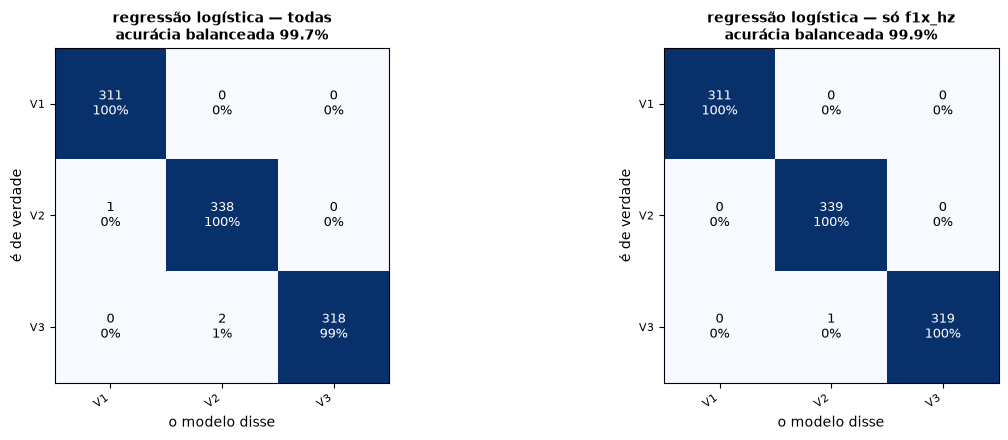

In [26]:
escolha_a = melhor_real(tabela_a.loc[[CONJUNTO_PRINCIPAL]])
previsto = previsoes_a[(escolha_a["modelo"], CONJUNTO_PRINCIPAL)]
print(f"Melhor modelo em '{CONJUNTO_PRINCIPAL}': {escolha_a['modelo']}")

linhas_reais = dev["rotulo_classe"].to_numpy()
tabela_erros = pd.crosstab(pd.Series(linhas_reais, name="classe real"), pd.Series(previsto, name="velocidade prevista")).reindex(ORDEM_CLASSES)
display(tabela_erros)

fig, axs = plt.subplots(1, 2, figsize=(13, 4.5))
plotar_matriz(dev["rotulo_velocidade"].to_numpy(), previsto, ORDEM_VELOCIDADES, f"{escolha_a['modelo']} — {CONJUNTO_PRINCIPAL}", ax=axs[0])
previsto_f1x = previsoes_a[(escolha_a["modelo"], "só f1x_hz")]
plotar_matriz(dev["rotulo_velocidade"].to_numpy(), previsto_f1x, ORDEM_VELOCIDADES, f"{escolha_a['modelo']} — só f1x_hz", ax=axs[1])
plt.tight_layout()
plt.show()

### Conclusões do Passo 8 (dados novos)

* **A velocidade é fácil com rótulos:** de 99,2% a 99,9% com FFT, rotação ou todas as features. **Só com `f1x_hz`, a regressão logística acerta 99,9%.**
* **Erros (todas as features):** só 3 janelas em 970. Uma do normal V2 foi para V1, e duas da Vel 3 (normal e papel) foram para V2.
* **O problema do K-Means sumiu:** sem rótulos, o começo frio do normal V2 ia para a Vel 3. Com rótulos, o modelo aprendeu a ignorar isso.
* **Com só as features de tempo, cai para 90% a 97%.** A magnitude da vibração muda com a falha, e a fita V2 vibra mais que muita coisa da Vel 3.
* **Atenção:** a faixa de rotação de cada velocidade fica larga com o aquecimento (Vel 1 de cerca de 11 a 13,4 Hz), mas ainda não encosta na faixa da velocidade vizinha (Vel 2 a partir de cerca de 17 Hz).

## Passo 9 — Tarefa B: normal ou anomalia?

**O que buscamos:** a detecção supervisionada (o **modelo 1** da arquitetura). Um modelo que viu exemplos de normal **e** das três falhas no treino, de todas as velocidades juntas, sem receber a velocidade, e responde só "normal" ou "anomalia".

**Lembretes do Notebook 04:**

* o K=2 global sem rótulos não detectou **nenhuma** falha da Vel 1 nem a porca;
* o K=2 com as falhas misturadas separou "a falha mais diferente" do resto.

Com rótulos, o modelo pode aprender a fronteira entre o normal e **todas** as falhas, mesmo as fracas.

**Como ler:**

* a tabela de modelos traz a acurácia balanceada e o pior recall (que aqui é o menor entre "recall do normal" e "recall da anomalia");
* a tabela **"% chamada de anomalia"** abre o resultado do modelo escolhido por condição e velocidade. Na linha do **normal**, o número é o **falso alarme**. Nas linhas das falhas, é o **recall daquela falha**. **Olhe a porca V2.**

In [27]:
def recall_por_velocidade(dev, previsto_binario):
    """Recall da anomalia por velocidade e falso alarme por velocidade."""
    linhas = []
    for v in ORDEM_VELOCIDADES:
        sel = (dev["rotulo_velocidade"] == v).to_numpy()
        reais = dev["rotulo_binario"].to_numpy()[sel]
        prev = np.asarray(previsto_binario)[sel]
        linhas.append({"velocidade": v,
                       f"recall {NOME_ANOMALIA} (%)": 100 * (prev[reais == NOME_ANOMALIA] == NOME_ANOMALIA).mean(),
                       "falso alarme (%)": 100 * (prev[reais == NOME_NORMAL] == NOME_ANOMALIA).mean()})
    return pd.DataFrame(linhas).set_index("velocidade")

acurácia (%)  \
features modelo                                         
tempo    referência: classe mais comum           75.3   
         referência: stump (1 pergunta)          73.2   
         regressão logística                     82.8   
         KNN (k=5)                               91.1   
         SVM (RBF)                               87.2   
         Random Forest                           91.4   
FFT      referência: classe mais comum           75.3   
         referência: stump (1 pergunta)          84.4   
         regressão logística                     99.6   
         KNN (k=5)                               97.5   
         SVM (RBF)                               99.3   
         Random Forest                           99.5   
rotação  referência: classe mais comum           75.3   
         referência: stump (1 pergunta)          75.3   
         regressão logística                     72.8   
         KNN (k=5)                               91.3   
         SVM (RBF)                               86.3   
         Random Forest                           89.9   
todas    referência: classe mais comum           75.3   
         referência: stump (1 pergunta)          84.4   
         regressão logística                     99.8   
         KNN (k=5)                               97.4   
         SVM (RBF)                               99.5   
         Random Forest                           99.2   

                                         acurácia balanceada (%)  \
features modelo                                                    
tempo    referência: classe mais comum                      50.0   
         referência: stump (1 pergunta)                     53.5   
         regressão logística                                76.4   
         KNN (k=5)                                          88.7   
         SVM (RBF)                                          81.9   
         Random Forest                                      89.1   
FFT      referência: classe mais comum                      50.0   
         referência: stump (1 pergunta)                     84.5   
         regressão logística                                99.7   
         KNN (k=5)                                          98.1   
         SVM (RBF)                                          99.5   
         Random Forest                                      99.7   
rotação  referência: classe mais comum                      50.0   
         referência: stump (1 pergunta)                     50.0   
         regressão logística                                53.9   
         KNN (k=5)                                          89.8   
         SVM (RBF)                                          76.8   
         Random Forest                                      83.2   
todas    referência: classe mais comum                      50.0   
         referência: stump (1 pergunta)                     84.5   
         regressão logística                                99.9   
         KNN (k=5)                                          98.0   
         SVM (RBF)                                          99.7   
         Random Forest                                      99.5   

                                         pior recall (%)  recall normal (%)  \
features modelo                                                               
tempo    referência: classe mais comum               0.0                0.0   
         referência: stump (1 pergunta)             14.6               14.6   
         regressão logística                        63.7               63.7   
         KNN (k=5)                                  83.8               83.8   
         SVM (RBF)                                  71.2               71.2   
         Random Forest                              84.6               84.6   
FFT      referência: classe mais comum               0.0                0.0   
         referência: stump (1 pergunta)             84.4               84.6   

Modelo escolhido em 'todas': regressão logística
% chamada de anomalia (linha do normal = falso alarme; linhas das falhas = recall daquela falha):


velocidade,V1,V2,V3
condicao,,,
normal,0.0,0.0,0.0
fita_1g,100.0,100.0,100.0
papel,100.0,100.0,100.0
porca_frouxa,100.0,97.7,100.0


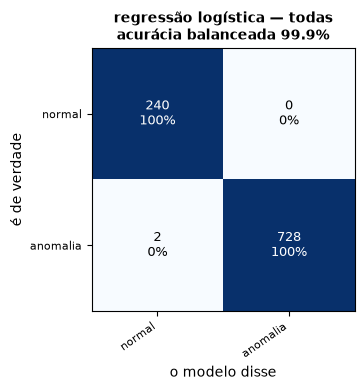

In [28]:
CLASSES_BINARIAS = [NOME_NORMAL, NOME_ANOMALIA]
tabela_b, previsoes_b = comparar_modelos(dev, CONJUNTOS, "rotulo_binario", CLASSES_BINARIAS, folds)
display(tabela_b.round(1))

escolha_b_principal = melhor_real(tabela_b.loc[[CONJUNTO_PRINCIPAL]])
previsto = previsoes_b[(escolha_b_principal["modelo"], CONJUNTO_PRINCIPAL)]
print(f"Modelo escolhido em '{CONJUNTO_PRINCIPAL}': {escolha_b_principal['modelo']}")
print("% chamada de anomalia (linha do normal = falso alarme; linhas das falhas = recall daquela falha):")
display(taxa_de_anomalia_por_condicao(dev, previsto).round(1))
plotar_matriz(dev["rotulo_binario"].to_numpy(), previsto, CLASSES_BINARIAS, f"{escolha_b_principal['modelo']} — {CONJUNTO_PRINCIPAL}")

### Conclusões do Passo 9 (dados novos)

**Os melhores (todas as features):**
* regressão logística: **99,9%** de acurácia balanceada, com pior recall de 99,7%;
* SVM: 99,7%;
* Random Forest: 99,5%;
* KNN: 98,0%.

**Por falha, com a regressão logística:**
* **falso alarme de 0%** nas três velocidades;
* fita e papel detectados 100%;
* **porca V2 detectada 97,7%**, e 100% nas outras velocidades.

**A porca V2 deixou de ser um problema.** Sem rótulos (Notebook 04), o K-Means separava "começo × fim" em vez de "porca × normal". **Com rótulos e blocos espalhados no tempo**, o modelo aprende o que o normal frio e o normal quente têm em comum, e acha a porca nos dois.

**O conjunto de features importa muito:**
* só **rotação**: a regressão logística cai para **53,9%**, pouco acima do acaso. A rotação quase não muda com papel e porca;
* só **tempo**: cai para 76% a 89%;
* **FFT**: 99,7%. Quem carrega a detecção são as **FFT**, como no Notebook 02.

**Comparação com os dados antigos:** lá, a detecção era quase toda feita por uma faixa de FFT (o stump acertava 95%). Aqui o stump acerta **84,5%**: o problema ficou mais difícil, e mesmo assim os modelos chegam perto de 100%.

## Passo 10 — Tarefa C: qual é a falha?

**O que buscamos:** o **diagnóstico**, o **modelo 2** da arquitetura. Ele só recebe janelas **que têm falha** e diz qual é: fita, papel ou porca. Na arquitetura "detector → tipo", é ele que é chamado quando o detector acusa uma anomalia.

**Por que treinar só com falhas:** na arquitetura final, o diagnóstico só vê janelas que o detector já acusou. Ele não precisa saber o que é "normal", só distinguir as falhas entre si. Isso é o que o Notebook 02 (Passo 10) mostrou ser possível: as três falhas se separam entre si em todas as velocidades, com o par **papel × porca na Vel 2** como o mais difícil.

**Os dados:** as janelas de falha do conjunto de desenvolvimento, com **os mesmos blocos**. A validação cruzada é refeita só com elas (5 rodadas, blocos inteiros, estratificada, com guarda).

**Como ler:** a tabela traz cada modelo e conjunto. A segunda tabela mostra o acerto do modelo escolhido por falha e velocidade. A matriz mostra para onde vão os erros.

Janelas de falha no desenvolvimento: 730


acurácia (%)  \
features modelo                                         
tempo    referência: classe mais comum           28.8   
         referência: stump (1 pergunta)          66.7   
         regressão logística                     87.7   
         KNN (k=5)                               98.4   
         SVM (RBF)                               97.3   
         Random Forest                           97.3   
FFT      referência: classe mais comum           28.8   
         referência: stump (1 pergunta)          58.8   
         regressão logística                     99.9   
         KNN (k=5)                               99.3   
         SVM (RBF)                               99.6   
         Random Forest                           99.3   
rotação  referência: classe mais comum           28.8   
         referência: stump (1 pergunta)          53.7   
         regressão logística                     93.0   
         KNN (k=5)                               97.4   
         SVM (RBF)                               95.1   
         Random Forest                           97.3   
todas    referência: classe mais comum           28.8   
         referência: stump (1 pergunta)          66.7   
         regressão logística                     99.5   
         KNN (k=5)                               99.2   
         SVM (RBF)                               99.3   
         Random Forest                           99.3   

                                         acurácia balanceada (%)  \
features modelo                                                    
tempo    referência: classe mais comum                      28.7   
         referência: stump (1 pergunta)                     66.7   
         regressão logística                                87.7   
         KNN (k=5)                                          98.4   
         SVM (RBF)                                          97.3   
         Random Forest                                      97.3   
FFT      referência: classe mais comum                      28.7   
         referência: stump (1 pergunta)                     58.6   
         regressão logística                                99.9   
         KNN (k=5)                                          99.3   
         SVM (RBF)                                          99.6   
         Random Forest                                      99.3   
rotação  referência: classe mais comum                      28.7   
         referência: stump (1 pergunta)                     53.7   
         regressão logística                                93.0   
         KNN (k=5)                                          97.4   
         SVM (RBF)                                          95.1   
         Random Forest                                      97.3   
todas    referência: classe mais comum                      28.7   
         referência: stump (1 pergunta)                     66.7   
         regressão logística                                99.5   
         KNN (k=5)                                          99.2   
         SVM (RBF)                                          99.3   
         Random Forest                                      99.3   

                                         pior recall (%)  recall fita_1g (%)  \
features modelo                                                                
tempo    referência: classe mais comum              17.4                32.9   
         referência: stump (1 pergunta)              0.0                 0.0   
         regressão logística                        82.3                82.3   
         KNN (k=5)                                  96.3                96.3   
         SVM (RBF)                                  93.8                93.8   
         Random Forest                              93.4                93.4   
FFT      referência: classe mais comum              17.4                32.9   
         referência: stump (1 pergunta)             32.6             

Modelo escolhido em 'todas': regressão logística
% de acerto por falha e velocidade:


velocidade,V1,V2,V3
condicao,,,
fita_1g,100.0,95.3,100.0
papel,100.0,100.0,100.0
porca_frouxa,100.0,100.0,100.0


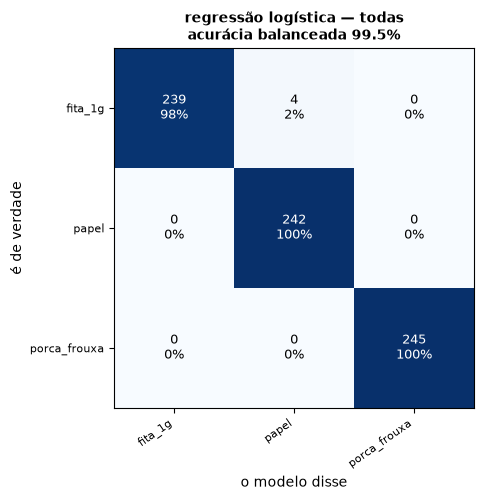

In [29]:
ORDEM_FALHAS = list(condicoes_comparadas)
dev_falhas = dev[dev["rotulo_binario"] == NOME_ANOMALIA].copy()
folds_falhas = montar_folds(dev_falhas)
print(f"Janelas de falha no desenvolvimento: {len(dev_falhas)}")

tabela_c, previsoes_c = comparar_modelos(dev_falhas, CONJUNTOS, "rotulo_condicao", ORDEM_FALHAS, folds_falhas)
display(tabela_c.round(1))

escolha_c_principal = melhor_real(tabela_c.loc[[CONJUNTO_PRINCIPAL]])
previsto = previsoes_c[(escolha_c_principal["modelo"], CONJUNTO_PRINCIPAL)]
print(f"Modelo escolhido em '{CONJUNTO_PRINCIPAL}': {escolha_c_principal['modelo']}")
print("% de acerto por falha e velocidade:")
display(acerto_por_condicao(dev_falhas, previsto).round(1))
plotar_matriz(dev_falhas["rotulo_condicao"].to_numpy(), previsto, ORDEM_FALHAS, f"{escolha_c_principal['modelo']} — {CONJUNTO_PRINCIPAL}")

### Conclusões do Passo 10 (dados novos)

* **O diagnóstico também é quase perfeito na validação:**
  * regressão logística com FFT: **99,9%** de acurácia balanceada;
  * com todas as features: 99,5%;
  * SVM e Random Forest: cerca de 99%.
* **Por falha, com a regressão logística e todas as features:**
  * papel e porca: 100% nas três velocidades;
  * fita: 100% nas Vel 1 e 3 e **95,3% na Vel 2**. Os erros da fita V2 vão para o papel.
* **O par difícil não foi o esperado.** O Notebook 02 apontava **papel × porca na Vel 2** como o mais difícil, mas aqui os dois ficaram em 100%. O erro apareceu em **fita × papel na Vel 2**: 4 janelas da fita chamadas de papel. Na Tarefa D (Passo 12.5), o erro equivalente está nas primeiras janelas da fita V2, o trecho em que a vibração ainda está crescendo (Notebook 03, Passo 6.3). Nesse trecho, a fita ainda não tem a força total e parece o papel.
* **Só com tempo, 88% a 98%:** as falhas diferem também em **onde** a energia está no espectro, e não só em quanto o ventilador vibra.

## Passo 11 — Tarefa D: a condição (normal, fita, papel ou porca), com três arquiteturas

**O que buscamos:** a resposta completa que o sistema precisa dar, **"qual é a condição do ventilador?"**, comparando as três arquiteturas do Passo 6:

1. **classificador único** (4 condições de uma vez);
2. **por velocidade** (velocidade → condição, com scaler local);
3. **detector → tipo** (normal ou anomalia → qual falha), a arquitetura "um modelo chama o outro".

**Todas recebem os mesmos dados e os mesmos folds.** Cada arquitetura usa o mesmo tipo de modelo nas suas etapas (por exemplo, Random Forest no detector e no diagnóstico).

**Por que não 12 classes (velocidade × condição)?** A velocidade já é a Tarefa A, que é fácil. Juntar velocidade e condição faria um erro de velocidade contar como erro de condição. Aqui a pergunta é só a **condição**. Quem precisar da velocidade usa a Tarefa A.

**Como ler:**

* a tabela traz a acurácia balanceada (média dos recalls das 4 condições) e o pior recall de cada combinação de modelo, conjunto e arquitetura;
* as matrizes mostram a melhor de cada arquitetura no `CONJUNTO_PRINCIPAL`;
* a última tabela abre a melhor combinação geral por condição e velocidade. **Olhe a porca V2.**

In [30]:
def comparar_arquiteturas(dados, conjuntos, folds, modelos=MODELOS):
    """Valida cada modelo e conjunto nas três arquiteturas. Treina com 'rotulo_classe' e avalia a condição prevista."""
    linhas, previsoes = [], {}
    reais = dados["rotulo_condicao"].to_numpy()
    for nome_conjunto, colunas in conjuntos.items():
        for nome_modelo, fabrica in modelos.items():
            arquiteturas = ["classificador único"] if nome_modelo.startswith("referência") else list(ARQUITETURAS)
            for nome_arquitetura in arquiteturas:
                construir = ARQUITETURAS[nome_arquitetura]
                previsto = validar(lambda: construir(fabrica, colunas), dados, colunas, "rotulo_classe", folds)
                previsoes[(nome_modelo, nome_conjunto, nome_arquitetura)] = previsto
                linhas.append({"features": nome_conjunto, "modelo": nome_modelo, "arquitetura": nome_arquitetura,
                               **metricas(reais, previsto, ORDEM_CONDICOES)})
    return pd.DataFrame(linhas).set_index(["features", "modelo", "arquitetura"]), previsoes

In [31]:
tabela_d, previsoes_d = comparar_arquiteturas(dev, CONJUNTOS, folds)
colunas_d = ["acurácia (%)", "acurácia balanceada (%)", "pior recall (%)"] + [f"recall {c} (%)" for c in ORDEM_CONDICOES]
display(tabela_d[colunas_d].round(1))

acurácia (%)  \
features modelo                         arquitetura                         
tempo    referência: classe mais comum  classificador único          20.9   
         referência: stump (1 pergunta) classificador único          46.2   
         regressão logística            classificador único          79.0   
                                        detector → tipo              76.7   
                                        por velocidade               86.0   
         KNN (k=5)                      classificador único          90.2   
                                        detector → tipo              90.2   
                                        por velocidade               89.6   
         SVM (RBF)                      classificador único          86.1   
                                        detector → tipo              85.4   
                                        por velocidade               87.9   
         Random Forest                  classificador único          90.4   
                                        detector → tipo              90.2   
                                        por velocidade               90.9   
FFT      referência: classe mais comum  classificador único          20.9   
         referência: stump (1 pergunta) classificador único          43.6   
         regressão logística            classificador único          99.4   
                                        detector → tipo              99.6   
                                        por velocidade               98.7   
         KNN (k=5)                      classificador único          97.3   
                                        detector → tipo              97.2   
                                        por velocidade               97.0   
         SVM (RBF)                      classificador único          99.2   
                                        detector → tipo              99.2   
                                        por velocidade               98.5   
         Random Forest                  classificador único          98.2   
                                        detector → tipo              99.1   
                                        por velocidade               98.0   
rotação  referência: classe mais comum  classificador único          20.9   
         referência: stump (1 pergunta) classificador único          38.0   
         regressão logística            classificador único          76.8   
                                        detector → tipo              67.9   
                                        por velocidade               91.9   
         KNN (k=5)                      classificador único          90.3   
                                        detector → tipo              89.7   
                                        por velocidade               90.9   
         SVM (RBF)                      classificador único          86.1   
                                        detector → tipo              83.6   
                                        por velocidade               91.9   
         Random Forest                  classificador único          90.0   
                                        detector → tipo              86.9   
                                        por velocidade               91.8   
todas    referência: classe mais comum  classificador único          20.9   
         referência: stump (1 pergunta) classificador único          46.2   
         regressão logística            classificador único          99.1   
                                        detector → tipo              99.6   
                                        por velocidade               98.7   
         KNN (k=5)                      classificador único          97.0   
                                        detector → tipo              97.0   
                                        por velocidade               96.8   
         SVM (RBF)                      classificador úni

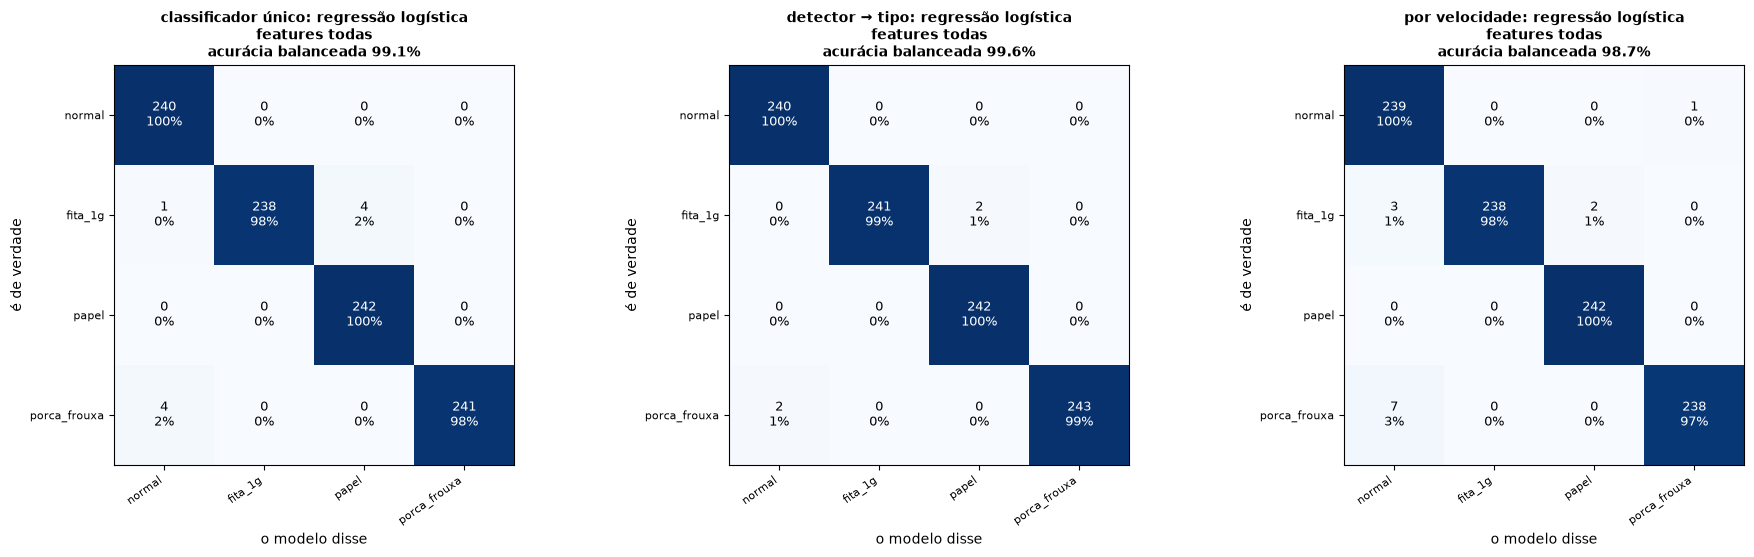

Melhor combinação geral pela regra: regressão logística, detector → tipo, features todas
% de acerto por condição e velocidade:


velocidade,V1,V2,V3
condicao,,,
normal,100.0,100.0,100.0
fita_1g,100.0,97.7,100.0
papel,100.0,100.0,100.0
porca_frouxa,100.0,97.7,100.0


In [32]:
reais_d = dev["rotulo_condicao"].to_numpy()
principal_d = sem_referencias(tabela_d.loc[[CONJUNTO_PRINCIPAL]])
fig, axs = plt.subplots(1, len(ARQUITETURAS), figsize=(6.2 * len(ARQUITETURAS), 5.6))
for ax, arquitetura in zip(axs, ARQUITETURAS):
    melhor = aplicar_regra_de_escolha(principal_d[principal_d.index.get_level_values("arquitetura") == arquitetura])
    previsto = previsoes_d[(melhor["modelo"], CONJUNTO_PRINCIPAL, arquitetura)]
    plotar_matriz(reais_d, previsto, ORDEM_CONDICOES, f"{arquitetura}: {melhor['modelo']}\nfeatures {CONJUNTO_PRINCIPAL}", ax=ax)
plt.tight_layout()
plt.show()

escolha_d_previa = melhor_real(tabela_d)
print(f"Melhor combinação geral pela regra: {escolha_d_previa['modelo']}, {escolha_d_previa['arquitetura']}, features {escolha_d_previa['features']}")
print("% de acerto por condição e velocidade:")
display(acerto_por_condicao(dev, previsoes_d[(escolha_d_previa["modelo"], escolha_d_previa["features"], escolha_d_previa["arquitetura"])]).round(1))

### Conclusões do Passo 11 (dados novos)

**Todas as features, melhor modelo de cada arquitetura:**

| Arquitetura | Modelo | Acurácia balanceada | Pior recall |
| --- | --- | --- | --- |
| Classificador único | regressão logística | 99,1% | 97,9% |
| **Detector → tipo** | regressão logística | **99,6%** | **99,2%** |
| Por velocidade | regressão logística | 98,7% | 97,1% |

* **As três arquiteturas ficam a menos de 1 ponto uma da outra**, e a "detector → tipo" é a melhor. **É uma boa notícia para a arquitetura planejada:** o "um modelo chama o outro" não perde nada em relação a um modelo único, e ainda é mais fácil de manter. Por exemplo, dá para trocar só o diagnóstico quando uma falha nova for coletada.
* **A arquitetura "por velocidade" é a pior com todas as features, mas a melhor com rotação** (91,9% contra 76,8% do único). Faz sentido: com poucas features, saber a velocidade ajuda. Com muitas, o modelo já se vira sozinho.
* **Por condição e velocidade (detector → tipo):**
  * normal, papel e porca V1 e V3: 100%;
  * **fita V2: 97,7%** e **porca V2: 97,7%**.
* **A regra de escolha nova fez diferença.** Com FFT e todas as features, a regressão logística "detector → tipo" empatou na média (99,6% e 99,6%). O desempate pelo **pior recall** (98,4% contra 99,2%) ficou com **todas as features**. Na regra antiga, teria ficado com o FFT, por ter menos features.

## Passo 12 — Testes anti-ilusão

**O que buscamos:** ter certeza de que os acertos vêm da **falha**, e não de um atalho. Todos usam **só o conjunto de desenvolvimento**: o teste trancado continua fechado.

1. **Rótulos embaralhados por bloco (12.1):** trocamos as condições entre os blocos ao acaso, de modo que cada bloco recebe a condição de outro, e refazemos a validação. Agora não existe relação real entre sinal e rótulo. **Um modelo honesto cai para perto do acaso** (1/4 = 25% de acurácia balanceada nas 4 condições). Se ele continuar acertando, há vazamento: o modelo está reconhecendo o bloco ou a gravação, e não a condição.
2. **Divisão cronológica nos dois sentidos (12.2):** treina no **começo** de cada gravação e testa no **fim**, e depois o contrário. **É o teste do aquecimento:** se o modelo depender de "motor frio" ou "motor quente", ele cai.
3. **O stump (12.3):** qual pergunta única o stump escolhe em cada tarefa e quanto ele acerta. Diz o quanto o problema é fácil.
4. **Quais features o Random Forest usou (12.4):** se o modelo se apoia em features com sentido físico, o resultado é mais confiável. Se o `f1x_hz` aparecer no topo da detecção, desconfie: ele mede rotação, que muda com o aquecimento.
5. **Erros no tempo (12.5):** onde, ao longo de cada gravação, a validação da Tarefa D errou.

### 12.1 — Rótulos embaralhados por bloco

**Como ler:** a primeira coluna é o resultado real (validação normal, classificador único, todas as features). As outras resumem os embaralhamentos. Se o real estiver muito acima de todos os embaralhados, o p-valor é o menor possível com `N_EMBARALHAMENTOS` repetições: 1 / (N + 1).

In [33]:
def embaralhar_por_bloco(dev, coluna_rotulo, gerador):
    """Troca os rótulos entre os blocos: cada bloco inteiro recebe o rótulo de outro bloco, ao acaso."""
    chave = dev["base"] + "|" + dev["bloco"].astype(str)
    rotulo_por_bloco = dev.groupby(chave)[coluna_rotulo].first()
    novo = pd.Series(gerador.permutation(rotulo_por_bloco.to_numpy()), index=rotulo_por_bloco.index)
    copia = dev.copy()
    copia[coluna_rotulo] = chave.map(novo).to_numpy()
    return copia


def testar_rotulos_embaralhados(dev, colunas, fabrica_modelo, folds, coluna_rotulo="rotulo_classe", n=N_EMBARALHAMENTOS):
    """Acurácia balanceada real e com rótulos embaralhados por bloco; p-valor do teste de permutação."""
    gerador = np.random.default_rng(SEMENTE)
    real = 100 * balanced_accuracy_score(dev[coluna_rotulo], validar(fabrica_modelo, dev, colunas, coluna_rotulo, folds))
    embaralhados = []
    for _ in range(n):
        falso = embaralhar_por_bloco(dev, coluna_rotulo, gerador)
        embaralhados.append(100 * balanced_accuracy_score(falso[coluna_rotulo], validar(fabrica_modelo, falso, colunas, coluna_rotulo, folds)))
    p_valor = (1 + sum(e >= real for e in embaralhados)) / (n + 1)
    return real, np.array(embaralhados), p_valor

In [34]:
linhas = []
for nome_modelo in ["regressão logística", "KNN (k=5)", "Random Forest"]:
    real, embaralhados, p_valor = testar_rotulos_embaralhados(
        dev, COLUNAS_TODAS, lambda: criar_pipeline(MODELOS[nome_modelo](), COLUNAS_TODAS), folds, coluna_rotulo="rotulo_condicao")
    linhas.append({"modelo": nome_modelo, "real (%)": real, "embaralhado: média (%)": embaralhados.mean(),
                   "embaralhado: máximo (%)": embaralhados.max(), "acaso (%)": 100 / len(ORDEM_CONDICOES), "p-valor": p_valor})
display(pd.DataFrame(linhas).set_index("modelo").round(3))

,real (%),embaralhado: média (%),embaralhado: máximo (%),acaso (%),p-valor
modelo,,,,,
regressão logística,99.077,24.057,31.937,25.0,0.048
KNN (k=5),97.033,23.893,36.386,25.0,0.048
Random Forest,98.261,23.167,35.818,25.0,0.048


### 12.2 — Divisão cronológica nos dois sentidos: o teste do aquecimento

**Como funciona:** em cada gravação, as janelas de desenvolvimento são divididas pelo tempo.

* **"começo → fim":** treina nos primeiros `FRACAO_INICIO_CRONOLOGICO` (70%) do tempo e testa nos últimos 30%. O modelo aprende com o motor **frio e morno** e é testado com o motor **quente**.
* **"fim → começo":** treina nos últimos 70% e testa nos primeiros 30%. Aprende com o motor **morno e quente** e é testado com o motor **frio**.

Nos dois casos há guarda entre treino e teste.

**Como ler:** compare com a validação por blocos (Passos 8 a 11). Se cair muito, o modelo depende do momento da gravação. O sentido "fim → começo" tende a ser o mais difícil, porque os primeiros minutos são os mais diferentes (Notebook 04: partida a frio da Vel 2, começo da fita V1).

In [35]:
def dividir_cronologicamente(dados, fracao=FRACAO_INICIO_CRONOLOGICO, sentido="começo → fim"):
    """Um único 'fold' pelo tempo dentro de cada gravação, com guarda entre treino e teste.

    'começo → fim': treino nos primeiros 'fracao' do tempo, teste no resto.
    'fim → começo': treino nos últimos 'fracao' do tempo, teste no começo.
    """
    posicao = dados.groupby("base")["janela"].rank(pct=True)
    no_teste = posicao > fracao if sentido == "começo → fim" else posicao <= 1 - fracao
    guarda = marcar_guarda(dados, no_teste)
    treino = np.where(~no_teste.to_numpy() & ~guarda.to_numpy())[0]
    teste = np.where(no_teste.to_numpy())[0]
    return [(treino, teste, np.where(guarda.to_numpy())[0])]

In [36]:
TAREFAS_CRONOLOGICAS = {
    "A: velocidade": (dev, "rotulo_velocidade", "rotulo_velocidade", ORDEM_VELOCIDADES),
    "B: normal x anomalia": (dev, "rotulo_binario", "rotulo_binario", CLASSES_BINARIAS),
    "C: qual falha": (dev_falhas, "rotulo_condicao", "rotulo_condicao", ORDEM_FALHAS),
    "D: condição (classificador único)": (dev, "rotulo_condicao", "rotulo_condicao", ORDEM_CONDICOES),
}
linhas = []
for tarefa, (dados, coluna_treino, coluna_real, classes) in TAREFAS_CRONOLOGICAS.items():
    for sentido in ("começo → fim", "fim → começo"):
        fold = dividir_cronologicamente(dados, sentido=sentido)
        teste = fold[0][1]
        for nome_modelo in ORDEM_SIMPLICIDADE:
            previsto = validar(lambda: criar_pipeline(MODELOS[nome_modelo](), COLUNAS_TODAS), dados, COLUNAS_TODAS, coluna_treino, fold)
            m = metricas(dados[coluna_real].to_numpy()[teste], previsto[teste], classes)
            linhas.append({"tarefa": tarefa, "sentido": sentido, "modelo": nome_modelo,
                           "acurácia balanceada (%)": m["acurácia balanceada (%)"], "pior recall (%)": m["pior recall (%)"]})
cronologico = pd.DataFrame(linhas)
display(cronologico.pivot_table(index=["tarefa", "modelo"], columns="sentido", values=["acurácia balanceada (%)", "pior recall (%)"]).round(1))

acurácia balanceada (%)  \
sentido                                                          começo → fim   
tarefa                            modelo                                        
A: velocidade                     KNN (k=5)                             100.0   
                                  Random Forest                          99.6   
                                  SVM (RBF)                              98.9   
                                  regressão logística                    99.6   
B: normal x anomalia              KNN (k=5)                              84.9   
                                  Random Forest                          89.7   
                                  SVM (RBF)                              96.6   
                                  regressão logística                    95.9   
C: qual falha                     KNN (k=5)                             100.0   
                                  Random Forest                         100.0   
                                  SVM (RBF)                             100.0   
                                  regressão logística                    98.2   
D: condição (classificador único) KNN (k=5)                              92.5   
                                  Random Forest                          97.3   
                                  SVM (RBF)                              97.9   
                                  regressão logística                    97.6   

                                                                    \
sentido                                               fim → começo   
tarefa                            modelo                             
A: velocidade                     KNN (k=5)                   85.8   
                                  Random Forest               93.6   
                                  SVM (RBF)                   91.2   
                                  regressão logística         88.5   
B: normal x anomalia              KNN (k=5)                   96.3   
                                  Random Forest               98.4   
                                  SVM (RBF)                   99.8   
                                  regressão logística         98.8   
C: qual falha                     KNN (k=5)                   96.8   
                                  Random Forest               97.7   
                                  SVM (RBF)                   98.1   
                                  regressão logística         97.2   
D: condição (classificador único) KNN (k=5)                   92.0   
                                  Random Forest               93.4   
                                  SVM (RBF)                   96.9   
                                  regressão logística         95.5   

                                                      pior recall (%)  \
sentido                                                  começo → fim   
tarefa                            modelo                                
A: velocidade                     KNN (k=5)                     100.0   
                                  Random Forest                  98.9   
                                  SVM (RBF)                      96.8   
                                  regressão logística            98.9   
B: normal x anomalia              KNN (k=5)                      69.9   
                                  Random Forest                  79.5   
                                  SVM (RBF)                      93.2   
                                  regressão logística            91.8   
C: qual falha                     KNN (k=5)                     100.0   
                                  Random Forest                 100.0   
                                  SVM (RBF)                     100.0   
                                  regressão logística            94.5   
D: condição (classificador único) KNN (k=5)                      69.9   
               

In [37]:
print("Tarefa B (regressão logística, todas as features) — % chamada de anomalia no teste de cada sentido")
print("(linha do normal = falso alarme; linhas das falhas = recall daquela falha)")
partes = {}
for sentido in ("começo → fim", "fim → começo"):
    fold = dividir_cronologicamente(dev, sentido=sentido)
    teste = fold[0][1]
    previsto = validar(lambda: criar_pipeline(MODELOS["regressão logística"](), COLUNAS_TODAS), dev, COLUNAS_TODAS, "rotulo_binario", fold)
    partes[sentido] = taxa_de_anomalia_por_condicao(dev.iloc[teste], previsto[teste])
display(pd.concat(partes, axis=1).round(1))

Tarefa B (regressão logística, todas as features) — % chamada de anomalia no teste de cada sentido
(linha do normal = falso alarme; linhas das falhas = recall daquela falha)


começo → fim               fim → começo              
velocidade             V1     V2     V3           V1     V2     V3
condicao                                                          
normal                0.0   24.0    0.0          0.0    0.0    0.0
fita_1g             100.0  100.0  100.0        100.0  100.0  100.0
papel               100.0  100.0  100.0        100.0  100.0  100.0
porca_frouxa        100.0  100.0  100.0        100.0   80.0  100.0

### 12.3 — O stump: qual pergunta única ele escolhe?

**Como ler:** para cada tarefa, a feature e o limite que a árvore de uma pergunta só escolheu (treinada em todo o desenvolvimento) e a acurácia balanceada dela na validação (das tabelas anteriores). Um stump com acerto alto mostra que **uma única feature** já resolve a tarefa. Com 3 ou 4 classes, uma pergunta só consegue separar no máximo 2 grupos, então o teto do stump é mais baixo nas Tarefas C e D.

In [38]:
def descrever_stump(dev, colunas, coluna_rotulo):
    """Treina o stump no desenvolvimento e devolve a pergunta que ele faz (feature e limite, na escala original)."""
    pipeline = criar_pipeline(MODELOS["referência: stump (1 pergunta)"](), colunas).fit(dev[colunas], dev[coluna_rotulo])
    arvore = pipeline.named_steps["modelo"]
    nomes = [c for c in colunas if c not in COLUNAS_SEM_LOG] + [c for c in colunas if c in COLUNAS_SEM_LOG]
    indice = arvore.tree_.feature[0]
    limite_padronizado = arvore.tree_.threshold[0]
    scaler = pipeline.named_steps["scaler"]
    limite_log = limite_padronizado * scaler.scale_[indice] + scaler.mean_[indice]
    feature = nomes[indice]
    limite = np.exp(limite_log) if feature not in COLUNAS_SEM_LOG else limite_log
    return feature, limite

In [39]:
linhas = []
for tarefa, dados, coluna, tabela in (("A: velocidade", dev, "rotulo_velocidade", tabela_a),
                                      ("B: normal x anomalia", dev, "rotulo_binario", tabela_b),
                                      ("C: qual falha", dev_falhas, "rotulo_condicao", tabela_c)):
    feature, limite = descrever_stump(dados, COLUNAS_TODAS, coluna)
    linhas.append({"tarefa": tarefa, "pergunta do stump": f"{feature} > {limite:.3g}?",
                   "acurácia balanceada na validação (%)": tabela.loc[("todas", "referência: stump (1 pergunta)"), "acurácia balanceada (%)"]})
display(pd.DataFrame(linhas).set_index("tarefa").round(1))

,pergunta do stump,acurácia balanceada na validação (%)
tarefa,,
A: velocidade,f1x_hz > 20.5?,63.6
B: normal x anomalia,fft_225_235Hz_x > 0.0539?,84.5
C: qual falha,pico_z > 4.32?,66.7


### 12.4 — Quais features o Random Forest usou?

**O que é a importância:** cada árvore do Random Forest faz perguntas sobre as features. A importância de uma feature é o quanto as perguntas sobre ela ajudaram a separar as classes, somado em todas as árvores (total = 1).

**Como ler:** as 15 mais importantes e, no gráfico da direita, a soma por tipo (tempo, FFT, rotação). **Cuidado:** quando várias features carregam a mesma informação (por exemplo, `std_x` e `pico_x`), a importância se divide entre elas. Uma feature com importância baixa não é necessariamente inútil, pode só ter uma "irmã" que levou o crédito.

**O que procurar nos dados novos:** na detecção (B), features de rotação no topo, principalmente o `f1x_hz`, seriam um sinal de que o modelo está usando o aquecimento. No diagnóstico (C), espera-se a 1X para a fita e faixas de FFT altas para papel e porca (Notebook 02).

In [40]:
def importancias_random_forest(dev, colunas, coluna_rotulo):
    """Importância de cada feature num Random Forest treinado em todo o desenvolvimento."""
    pipeline = criar_pipeline(MODELOS["Random Forest"](), colunas).fit(dev[colunas], dev[coluna_rotulo])
    nomes = [c for c in colunas if c not in COLUNAS_SEM_LOG] + [c for c in colunas if c in COLUNAS_SEM_LOG]
    return pd.Series(pipeline.named_steps["modelo"].feature_importances_, index=nomes).sort_values(ascending=False)


def tipo_da_feature(nome):
    if nome.startswith(("std_", "kurt_", "pico_")):
        return "tempo"
    return "FFT" if nome.startswith("fft_") else "rotação"

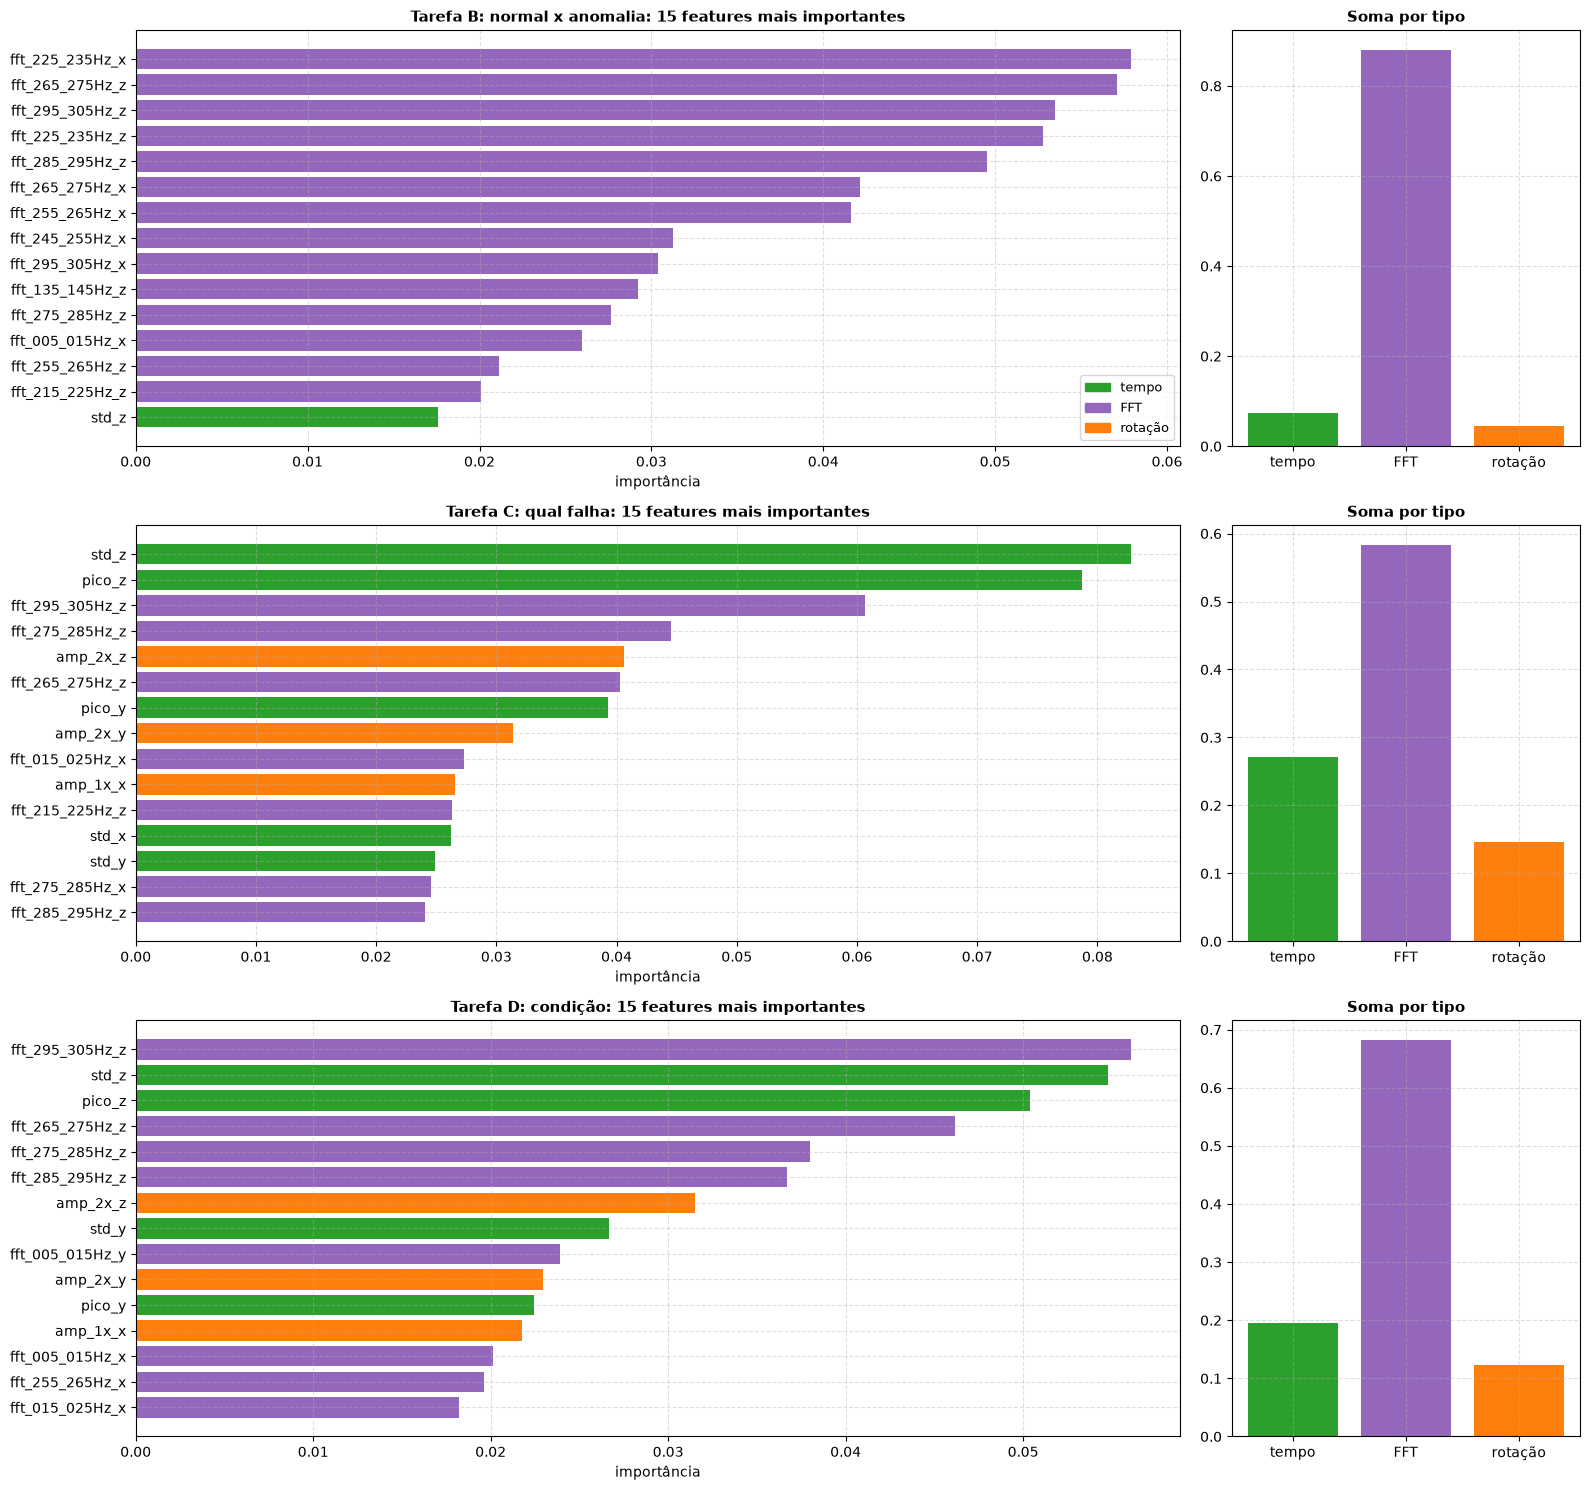

In [41]:
fig, axs = plt.subplots(3, 2, figsize=(16, 15), gridspec_kw={"width_ratios": [3, 1]})
for linha, (tarefa, dados, coluna) in enumerate((("B: normal x anomalia", dev, "rotulo_binario"),
                                                  ("C: qual falha", dev_falhas, "rotulo_condicao"),
                                                  ("D: condição", dev, "rotulo_condicao"))):
    importancias = importancias_random_forest(dados, COLUNAS_TODAS, coluna)
    top = importancias.head(15)[::-1]
    axs[linha, 0].barh(top.index, top.values, color=[CORES_TIPO[tipo_da_feature(n)] for n in top.index])
    axs[linha, 0].set_title(f"Tarefa {tarefa}: 15 features mais importantes", fontsize=11, fontweight="bold")
    axs[linha, 0].set_xlabel("importância")
    por_tipo = importancias.groupby(importancias.index.map(tipo_da_feature)).sum().reindex(list(CORES_TIPO))
    axs[linha, 1].bar(por_tipo.index, por_tipo.values, color=[CORES_TIPO[t] for t in por_tipo.index])
    axs[linha, 1].set_title("Soma por tipo", fontsize=11, fontweight="bold")
axs[0, 0].legend(handles=[Patch(color=c, label=t) for t, c in CORES_TIPO.items()], fontsize=9)
plt.tight_layout()
plt.show()

### 12.5 — Erros no tempo (validação cruzada da Tarefa D)

**Como ler:** cada faixa é uma gravação, com as janelas de desenvolvimento em ordem de tempo. **Verde = acerto, X vermelho = erro** da melhor combinação da Tarefa D na validação cruzada. O título de cada faixa diz quantos erros houve e, entre parênteses, **para qual condição** as janelas erradas foram mandadas. O que procurar:

* **erros juntos no começo** de uma gravação das Vel 1 e 2: motor frio (aquecimento);
* **erros em ritmo regular:** ciclo da oscilação;
* **erros espalhados:** ruído.

In [42]:
def plotar_erros_no_tempo(dados, previsto, titulo, coluna_real="rotulo_condicao"):
    """Acerto (verde) ou erro (X vermelho) de cada janela, por gravação, em ordem de tempo."""
    bases_ordenadas = sorted(dados["base"].unique(), key=lambda b: (b.split("_vel_")[1], b))
    fig, axs = plt.subplots(len(bases_ordenadas), 1, figsize=(14, 0.9 * len(bases_ordenadas) + 1.2), sharex=True, squeeze=False)
    for ax, base in zip(axs[:, 0], bases_ordenadas):
        sel = (dados["base"] == base).to_numpy()
        janelas = dados["janela"].to_numpy()[sel]
        previsto_base = np.asarray(previsto)[sel]
        acerto = previsto_base == dados[coluna_real].to_numpy()[sel]
        ax.scatter(janelas[acerto], np.zeros(acerto.sum()), s=10, color="tab:green")
        ax.scatter(janelas[~acerto], np.zeros((~acerto).sum()), s=30, color="tab:red", marker="x")
        ax.set_yticks([])
        destinos = pd.Series(previsto_base[~acerto]).value_counts()
        texto_destinos = f" (foram para: {', '.join(f'{d} {n}' for d, n in destinos.items())})" if len(destinos) else ""
        ax.set_title(f"{base}: {(~acerto).sum()} erros em {len(acerto)} janelas{texto_destinos}", fontsize=9, fontweight="bold", loc="left")
    axs[-1, 0].set_xlabel(f"janela (cada uma = {JANELA_S} s)")
    fig.suptitle(titulo, fontsize=12, fontweight="bold")
    plt.tight_layout(rect=[0, 0, 1, 0.95])
    plt.show()

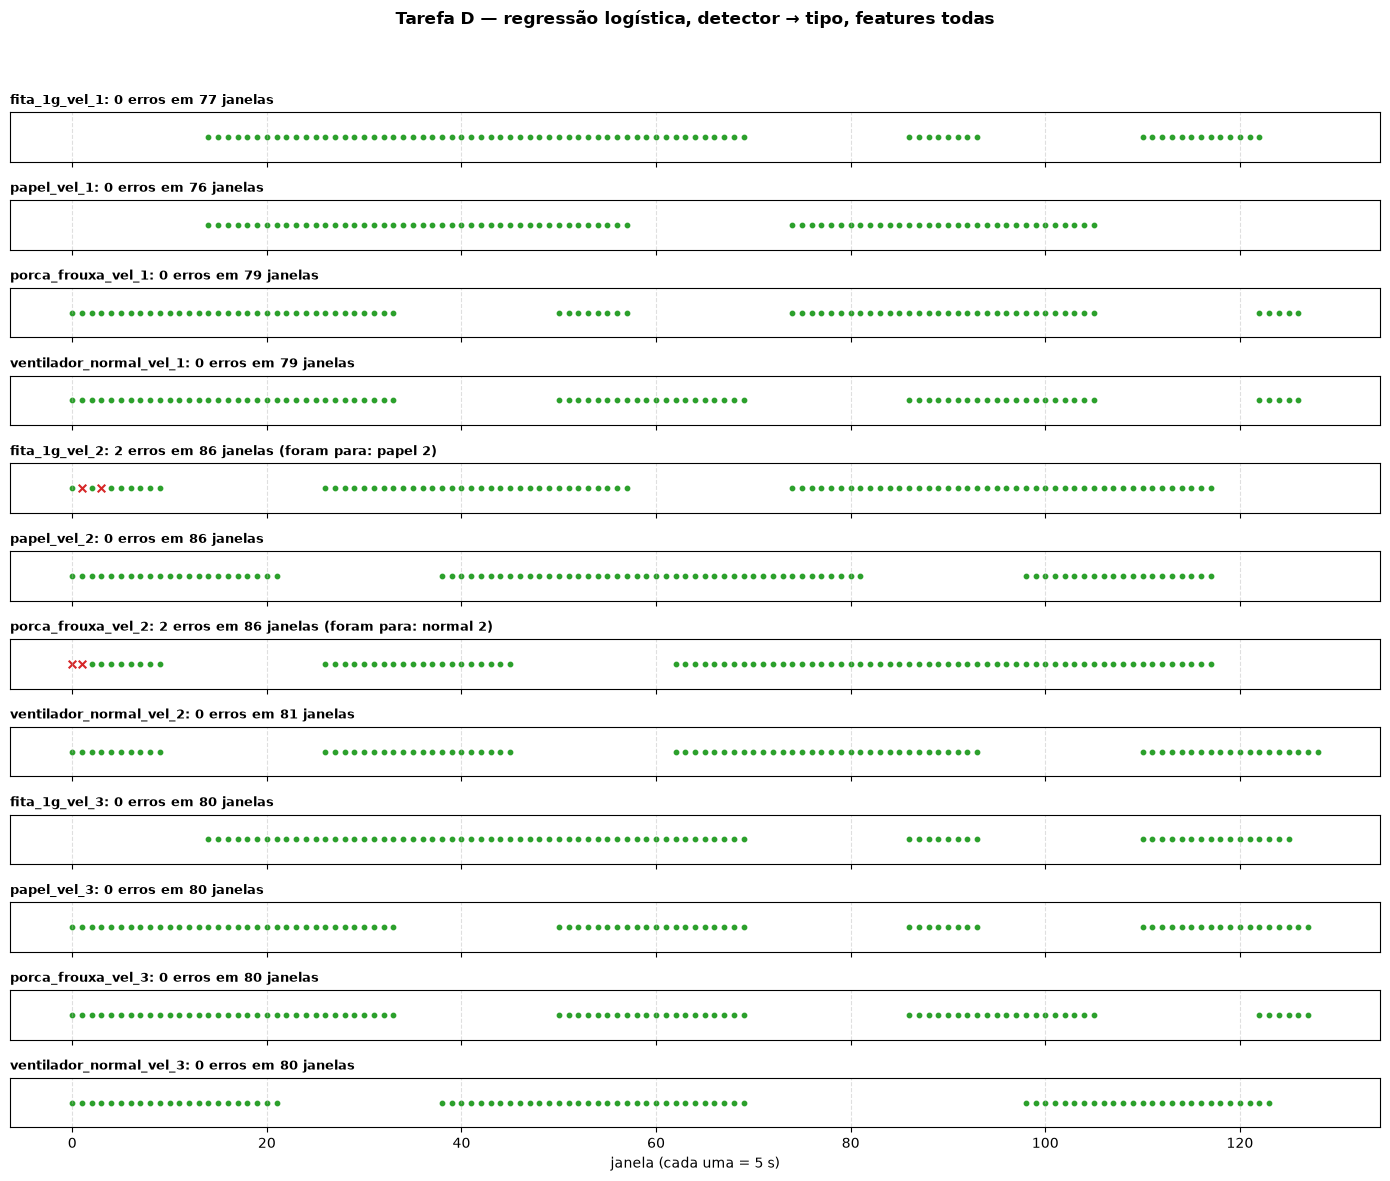

In [43]:
plotar_erros_no_tempo(dev, previsoes_d[(escolha_d_previa["modelo"], escolha_d_previa["features"], escolha_d_previa["arquitetura"])],
                      f"Tarefa D — {escolha_d_previa['modelo']}, {escolha_d_previa['arquitetura']}, features {escolha_d_previa['features']}")

### Conclusões do Passo 12 (dados novos)

**12.1 — Rótulos embaralhados:**
* com rótulos embaralhados, os modelos caem para cerca de **24%**, o acaso das 4 condições (25%). O máximo foi 36%;
* o resultado real fica entre 97% e 99%, com p-valor de 0,048, o menor possível com 20 repetições;
* **não há sinal de que o modelo reconheça blocos ou gravações** em vez da condição.

**12.2 — Divisão cronológica: o aquecimento aparece, e de um jeito previsível.**

| Tarefa B (regressão logística, todas) | começo → fim | fim → começo |
| --- | --- | --- |
| Acurácia balanceada | 95,9% | 98,8% |
| Falso alarme no normal V2 | **24%** | 0% |
| Recall da porca V2 | 100% | **80%** |

* **Treinado no motor frio e testado no quente:** o modelo acusa **o normal V2 quente** como falha.
* **Treinado no quente e testado no frio:** ele deixa passar **a porca V2 fria**.
* **É exatamente a confusão do K-Means** (Notebook 04): **normal V2 e porca V2 se confundem entre "frio" e "quente"**. O KNN sofre mais (até 46% de falso alarme no normal num sentido, 64% da porca V2 perdida no outro). O SVM e a regressão logística sofrem menos.
* **Conclusão:** os 99,9% da validação por blocos dependem de o treino ter visto **o motor frio e o quente**. Um modelo treinado só com um estado térmico erra no outro. **Para o sistema real, a calibração precisa cobrir o ventilador recém-ligado e já aquecido.**
* **Tarefa A (velocidade) com todas as features, "fim → começo":** cai para 86% a 94%. **Só com `f1x_hz`, fica em 99,7%.** Mais um motivo para a etapa de velocidade usar só a rotação.

**12.3 — Stump:**

| Tarefa | Pergunta | Acurácia balanceada |
| --- | --- | --- |
| A (velocidade) | "`f1x_hz` > 20,5?" | 64% |
| B (detecção) | "FFT de 225–235 Hz no eixo x > 0,054?" | 84,5% |
| C (qual falha) | "`pico_z` > 4,32?" | 67% |

* Na Tarefa A, uma pergunta só separa duas velocidades das três, por isso o teto é baixo.
* Na Tarefa B, uma pergunta só não basta (nos dados antigos acertava 95%). O problema ficou mais difícil.

**12.4 — Importâncias:**
* **Detecção (B):** quase só FFT de **alta frequência**, 225–305 Hz (88% da importância). O `f1x_hz` **não aparece**: o modelo não usa a rotação, o que é bom, porque a rotação muda com o aquecimento.
* **Diagnóstico (C) e condição (D):** `std_z` e `pico_z` no topo, depois FFT alta no eixo Z e as harmônicas `amp_2x` e `amp_1x`. A fita usa as harmônicas e o papel e a porca usam as altas frequências, coerente com o Notebook 02.

**12.5 — Erros no tempo (Tarefa D):** só **4 erros em 970 janelas**, todos nas **primeiras 4 janelas** de uma gravação (os primeiros 20 s):
* fita V2: 2 erros, que foram para papel;
* porca V2: 2 erros, que foram para normal.

É a **partida do motor**.

## Passo 13 — Escolha final e abertura do teste trancado

**A regra é a do Passo 7, decidida antes de qualquer resultado.** Ela é aplicada às quatro tarefas, olhando **todos** os conjuntos de features (e, na Tarefa D, todas as arquiteturas).

**A abertura:** cada modelo escolhido é treinado de novo com **todo o conjunto de desenvolvimento** e avaliado **uma vez** no teste trancado (um bloco do começo, um do meio e um do fim de cada gravação). Na Tarefa C (qual falha), o treino e o teste usam só as janelas de falha.

**Como ler:** se o trancado ficar perto da validação cruzada, a estimativa era confiável. Se ficar bem abaixo, a validação estava otimista (ou as escolhas "decoraram" a validação), e o número que vale para o TCC é **o do trancado**. As tabelas por condição e velocidade mostram se o trancado confirma o caso difícil (porca V2) e a lista no fim diz **em qual terço da gravação** cada erro aconteceu.

> **Não volte para mudar escolhas depois de ver o trancado.** Se precisar mudar, o trancado atual vira "usado", e um novo teste só é honesto com dados que ainda não foram vistos: a próxima coleta.

In [44]:
escolhas = {"A: velocidade": melhor_real(tabela_a),
            "B: normal x anomalia": melhor_real(tabela_b),
            "C: qual falha": melhor_real(tabela_c),
            "D: condição": melhor_real(tabela_d)}
tabela_escolhas = pd.DataFrame({tarefa: {"modelo": e["modelo"], "features": e["features"],
                                         "arquitetura": e.get("arquitetura", "—"),
                                         "acurácia balanceada na validação (%)": round(e["acurácia balanceada (%)"], 2),
                                         "pior recall na validação (%)": round(e["pior recall (%)"], 2)}
                                for tarefa, e in escolhas.items()}).T
display(tabela_escolhas)

,modelo,features,arquitetura,acurácia balanceada na validação (%),pior recall na validação (%)
A: velocidade,regressão logística,só f1x_hz,—,99.9,99.69
B: normal x anomalia,regressão logística,FFT,—,99.73,99.45
C: qual falha,regressão logística,FFT,—,99.86,99.59
D: condição,regressão logística,todas,detector → tipo,99.59,99.18


### 13.1 — Abrindo o teste trancado (uma vez só)

In [45]:
trancado_falhas = trancado[trancado["rotulo_binario"] == NOME_ANOMALIA].copy()
TAREFAS = {
    "A: velocidade": {"treino": dev, "teste": trancado, "rotulo_treino": "rotulo_velocidade", "rotulo_real": "rotulo_velocidade", "classes": ORDEM_VELOCIDADES},
    "B: normal x anomalia": {"treino": dev, "teste": trancado, "rotulo_treino": "rotulo_binario", "rotulo_real": "rotulo_binario", "classes": CLASSES_BINARIAS},
    "C: qual falha": {"treino": dev_falhas, "teste": trancado_falhas, "rotulo_treino": "rotulo_condicao", "rotulo_real": "rotulo_condicao", "classes": ORDEM_FALHAS},
    "D: condição": {"treino": dev, "teste": trancado, "rotulo_treino": "rotulo_classe", "rotulo_real": "rotulo_condicao", "classes": ORDEM_CONDICOES},
}


def construir_modelo(escolha):
    """Monta o modelo escolhido (pipeline simples ou uma das arquiteturas da Tarefa D)."""
    colunas = CONJUNTOS_TODOS[escolha["features"]]
    fabrica = MODELOS[escolha["modelo"]]
    if isinstance(escolha.get("arquitetura"), str):
        return ARQUITETURAS[escolha["arquitetura"]](fabrica, colunas)
    return criar_pipeline(fabrica(), colunas)


def treinar_modelos_finais(escolhas, tarefas=TAREFAS):
    """Treina cada modelo escolhido com todo o desenvolvimento da sua tarefa."""
    finais = {}
    for tarefa, e in escolhas.items():
        t = tarefas[tarefa]
        colunas = CONJUNTOS_TODOS[e["features"]]
        finais[tarefa] = construir_modelo(e).fit(t["treino"][colunas], t["treino"][t["rotulo_treino"]])
    return finais


def terco_da_janela(dados):
    """Em qual terço da gravação (começo, meio, fim) cada janela está."""
    posicao = dados.groupby("base")["janela"].rank(pct=True)
    return np.select([posicao <= 1 / 3, posicao <= 2 / 3], ["começo", "meio"], "fim")

,modelo,features,arquitetura,validação cruzada: acurácia balanceada (%),teste trancado: acurácia balanceada (%),teste trancado: pior recall (%),janelas no trancado
tarefa,,,,,,,
A: velocidade,regressão logística,só f1x_hz,—,99.90,100.00,100.00,423
B: normal x anomalia,regressão logística,FFT,—,99.73,99.52,99.05,423
C: qual falha,regressão logística,FFT,—,99.86,99.05,97.14,315
D: condição,regressão logística,todas,detector → tipo,99.59,99.05,96.19,423


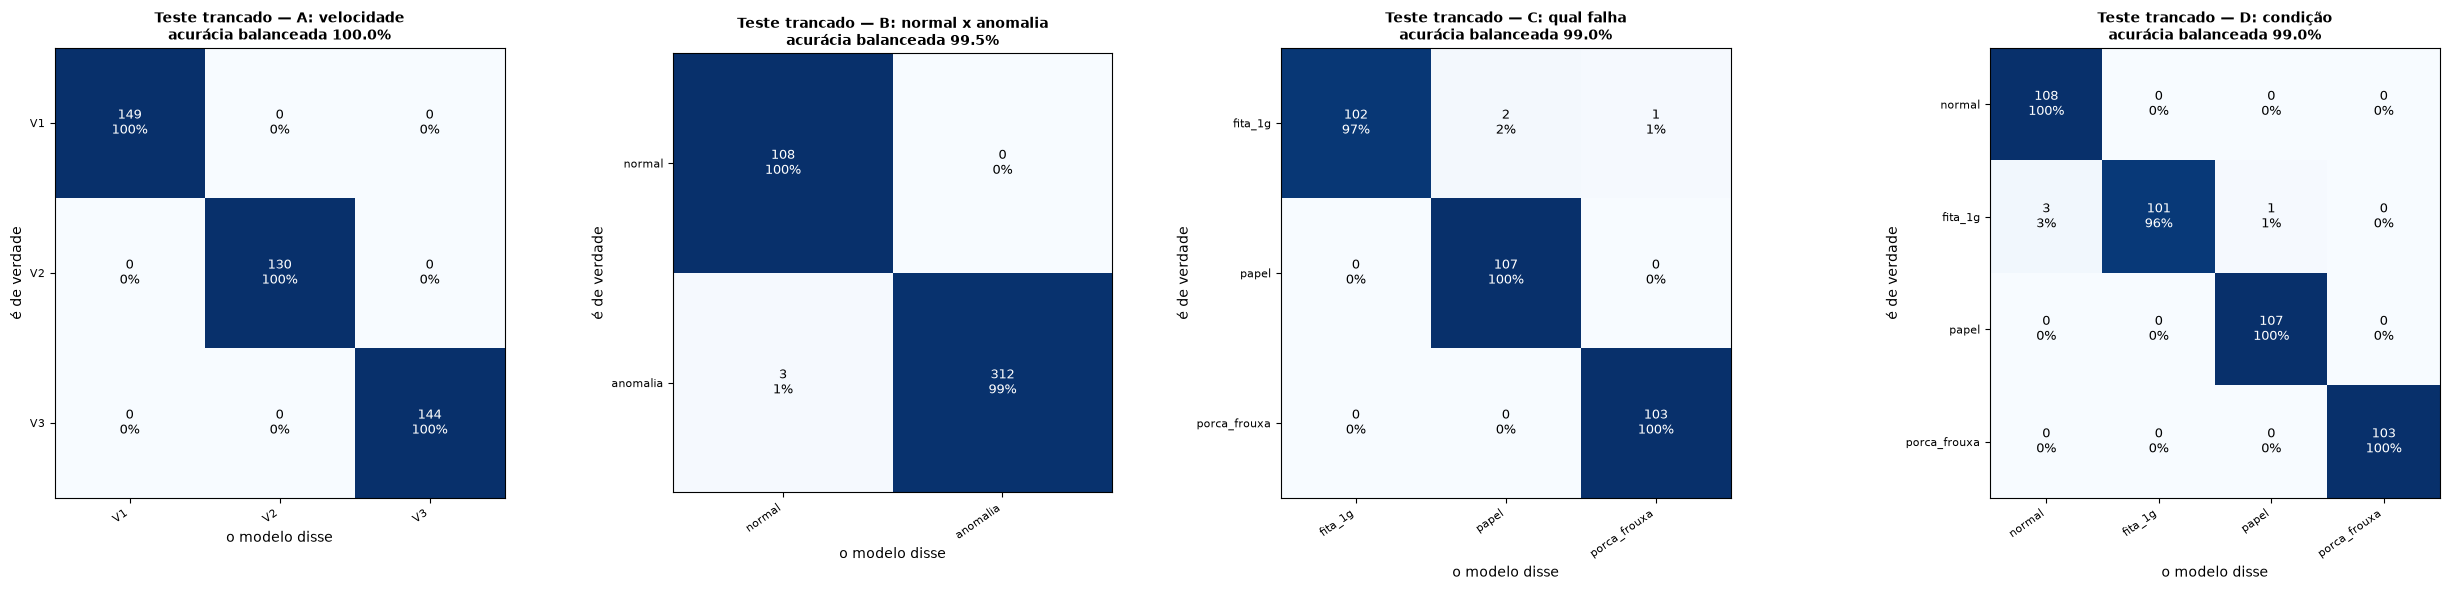

In [46]:
modelos_finais = treinar_modelos_finais(escolhas)
terco_trancado = pd.Series(terco_da_janela(features), index=features.index)

resultados_trancado, linhas = {}, []
for tarefa, t in TAREFAS.items():
    colunas = CONJUNTOS_TODOS[escolhas[tarefa]["features"]]
    previsto = modelos_finais[tarefa].predict(t["teste"][colunas])
    resultados_trancado[tarefa] = previsto
    m = metricas(t["teste"][t["rotulo_real"]], previsto, t["classes"])
    linhas.append({"tarefa": tarefa, "modelo": escolhas[tarefa]["modelo"], "features": escolhas[tarefa]["features"],
                   "arquitetura": escolhas[tarefa].get("arquitetura", "—"),
                   "validação cruzada: acurácia balanceada (%)": escolhas[tarefa]["acurácia balanceada (%)"],
                   "teste trancado: acurácia balanceada (%)": m["acurácia balanceada (%)"],
                   "teste trancado: pior recall (%)": m["pior recall (%)"],
                   "janelas no trancado": len(t["teste"])})
display(pd.DataFrame(linhas).set_index("tarefa").round(2))

fig, axs = plt.subplots(1, 4, figsize=(26, 6), gridspec_kw={"width_ratios": [1, 0.8, 1, 1.15]})
for ax, (tarefa, t) in zip(axs, TAREFAS.items()):
    plotar_matriz(t["teste"][t["rotulo_real"]].to_numpy(), resultados_trancado[tarefa], t["classes"], f"Teste trancado — {tarefa}", ax=ax)
plt.tight_layout()
plt.show()

In [47]:
print("Tarefa B no trancado — % chamada de anomalia (linha do normal = falso alarme):")
display(taxa_de_anomalia_por_condicao(trancado, resultados_trancado["B: normal x anomalia"]).round(1))
print("Tarefa C no trancado — % de acerto por falha e velocidade:")
display(acerto_por_condicao(trancado_falhas, resultados_trancado["C: qual falha"]).round(1))
print("Tarefa D no trancado — % de acerto por condição e velocidade:")
display(acerto_por_condicao(trancado, resultados_trancado["D: condição"]).round(1))

for tarefa, t in TAREFAS.items():
    errados = t["teste"][resultados_trancado[tarefa] != t["teste"][t["rotulo_real"]].to_numpy()]
    if len(errados) == 0:
        print(f"Erros no trancado — {tarefa}: nenhum")
        continue
    previsto_errado = pd.Series(resultados_trancado[tarefa], index=t["teste"].index)[errados.index]
    resumo = (pd.DataFrame({"base": errados["base"], "terço": terco_trancado[errados.index], "disse": previsto_errado})
              .groupby(["base", "terço", "disse"]).size().rename("janelas"))
    print(f"Erros no trancado — {tarefa}:")
    display(resumo.to_frame())

Tarefa B no trancado — % chamada de anomalia (linha do normal = falso alarme):


velocidade,V1,V2,V3
condicao,,,
normal,0.0,0.0,0.0
fita_1g,91.7,100.0,100.0
papel,100.0,100.0,100.0
porca_frouxa,100.0,100.0,100.0


Tarefa C no trancado — % de acerto por falha e velocidade:


velocidade,V1,V2,V3
condicao,,,
fita_1g,97.2,93.9,100.0
papel,100.0,100.0,100.0
porca_frouxa,100.0,100.0,100.0


Tarefa D no trancado — % de acerto por condição e velocidade:


velocidade,V1,V2,V3
condicao,,,
normal,100.0,100.0,100.0
fita_1g,91.7,97.0,100.0
papel,100.0,100.0,100.0
porca_frouxa,100.0,100.0,100.0


... (2 outputs left out)

Erros no trancado — C: qual falha:


,,,janelas
base,terço,disse,
fita_1g_vel_1,começo,porca_frouxa,1
fita_1g_vel_2,começo,papel,2


Erros no trancado — D: condição:


,,,janelas
base,terço,disse,
fita_1g_vel_1,começo,normal,3
fita_1g_vel_2,começo,papel,1


### Resultado do teste trancado (dados novos)

| Tarefa | Modelo escolhido | Validação | **Trancado** | Pior recall no trancado |
| --- | --- | --- | --- | --- |
| A: velocidade | regressão logística, só `f1x_hz` | 99,9% | **100%** | 100% |
| B: normal × anomalia | regressão logística, FFT | 99,7% | **99,5%** | 99,1% |
| C: qual falha | regressão logística, FFT | 99,9% | **99,1%** | 97,1% |
| D: condição | regressão logística, detector → tipo, todas | 99,6% | **99,1%** | 96,2% |

* **O trancado confirma a validação:** a diferença é de no máximo 0,8 ponto. A estimativa era confiável.
* **Falso alarme no trancado: 0%** nas três velocidades. **Porca V2: 100%** na detecção e na condição.
* **Todos os erros (4 na Tarefa D) estão no terço do começo**, e todos envolvem a **fita**:
  * **fita V1:** 3 janelas do primeiro minuto (bloco 0) chamadas de normal;
  * **fita V2:** 1 janela chamada de papel.
  * É o mesmo padrão de antes: **o desbalanceamento da fita ainda não está "completo" com o motor frio**. Isso já tinha aparecido no K-Means (fita V1 nos primeiros 3 minutos) e no Notebook 03 (fita V2 crescendo nos primeiros 4 minutos).
* **O modelo final é o mais simples da lista em todas as tarefas** (regressão logística). Com estes dados, uma fronteira linear basta.

## Passo 14 — Teste em outra sessão: treinar nos dados novos, testar nos antigos

**O que buscamos:** a pergunta que nenhum teste dentro da sessão responde: **o modelo funciona num outro dia de gravação?** Os dados antigos (pasta `BASES_ROTULADAS`) foram gravados em outra sessão, com **normal e fita 1g** nas três velocidades. Eles **nunca** entraram em nenhuma escolha deste notebook.

**Como fazemos:**

1. Carregamos as bases antigas com **a mesma receita**: o mesmo corte de 5 s no começo e no fim, as mesmas janelas de 5 s e as mesmas 109 features.
2. Usamos **os mesmos modelos do Passo 13**, já treinados com o desenvolvimento dos dados novos. Nada é re-treinado nem ajustado.
3. Avaliamos as tarefas que fazem sentido com normal e fita:
   * **A (velocidade):** todas as janelas antigas;
   * **B (normal × anomalia):** todas, com a fita como anomalia;
   * **C (qual falha):** só as janelas de fita. O certo é responder "fita_1g";
   * **D (condição):** todas. O certo é "normal" ou "fita_1g". Os erros podem cair em **papel** ou **porca**, que não existem nos dados antigos.

**O que esperar e como ler:** se os números ficarem perto dos do trancado, o modelo aprendeu a falha e não "esta gravação". Se caírem muito, existe um **efeito de sessão**: o sensor, a montagem ou o ventilador estavam diferentes naquele dia, e o modelo não sobrevive à mudança. O Notebook 02 dos dados antigos já tinha visto que o normal antigo e o novo diferem em várias features, por isso uma queda **é possível e é informação importante**, não um erro do código.

**Atenção:** este teste também só pode ser lido **uma vez**. Não mude modelos depois de vê-lo.

In [48]:
def preparar_outra_sessao(pasta):
    """Carrega outra sessão com a mesma receita (corte, janelas, 109 features) e os mesmos rótulos."""
    bases_outra, catalogo_outra = carregar_todas_as_bases(pasta)
    bases_outra, catalogo_outra = aparar_bases(bases_outra, catalogo_outra)
    tabela, freq, espectros = analisar_todas_as_bases(bases_outra, catalogo_outra)
    tabela = adicionar_colunas_de_rotacao(tabela, freq, espectros)
    tabela = tabela.sort_values(["base", "janela"]).reset_index(drop=True)
    eh_normal_outra = tabela["condicao"].isin(CONDICOES_REFERENCIA)
    tabela["rotulo_condicao"] = np.where(eh_normal_outra, NOME_NORMAL, tabela["condicao"])
    tabela["rotulo_binario"] = np.where(eh_normal_outra, NOME_NORMAL, NOME_ANOMALIA)
    tabela["rotulo_velocidade"] = "V" + tabela["velocidade"].astype(str)
    tabela["rotulo_classe"] = tabela["rotulo_condicao"] + " " + tabela["rotulo_velocidade"]
    return tabela

In [49]:
outra_sessao = preparar_outra_sessao(PASTA_OUTRA_SESSAO)
outra_falhas = outra_sessao[outra_sessao["rotulo_binario"] == NOME_ANOMALIA]
print("Janelas da outra sessão por condição e velocidade:")
display(outra_sessao.groupby(["rotulo_velocidade", "rotulo_condicao"]).size().unstack())

TAREFAS_OUTRA = {
    "A: velocidade": (outra_sessao, "rotulo_velocidade", ORDEM_VELOCIDADES),
    "B: normal x anomalia": (outra_sessao, "rotulo_binario", CLASSES_BINARIAS),
    "C: qual falha": (outra_falhas, "rotulo_condicao", ORDEM_FALHAS),
    "D: condição": (outra_sessao, "rotulo_condicao", ORDEM_CONDICOES),
}
resultados_outra, linhas = {}, []
for tarefa, (dados, coluna, classes) in TAREFAS_OUTRA.items():
    colunas = CONJUNTOS_TODOS[escolhas[tarefa]["features"]]
    previsto = modelos_finais[tarefa].predict(dados[colunas])
    resultados_outra[tarefa] = previsto
    m = metricas(dados[coluna], previsto, classes)
    trancado_m = metricas(TAREFAS[tarefa]["teste"][TAREFAS[tarefa]["rotulo_real"]], resultados_trancado[tarefa], classes)
    linhas.append({"tarefa": tarefa, "classes presentes na outra sessão": ", ".join(c for c in classes if (dados[coluna] == c).any()),
                   "teste trancado (mesma sessão): acurácia balanceada (%)": trancado_m["acurácia balanceada (%)"],
                   "outra sessão: acurácia balanceada (%)": m["acurácia balanceada (%)"],
                   "outra sessão: pior recall (%)": m["pior recall (%)"]})
display(pd.DataFrame(linhas).set_index("tarefa").round(2))

Janelas da outra sessão por condição e velocidade:


rotulo_condicao,fita_1g,normal
rotulo_velocidade,,
V1,110,118
V2,108,112
V3,116,100


,classes presentes na outra sessão,teste trancado (mesma sessão): acurácia balanceada (%),outra sessão: acurácia balanceada (%),outra sessão: pior recall (%)
tarefa,,,,
A: velocidade,"V1, V2, V3",100.00,100.00,100.00
B: normal x anomalia,"normal, anomalia",99.52,85.48,71.56
C: qual falha,fita_1g,99.05,100.00,100.00
D: condição,"normal, fita_1g",99.05,86.38,72.75


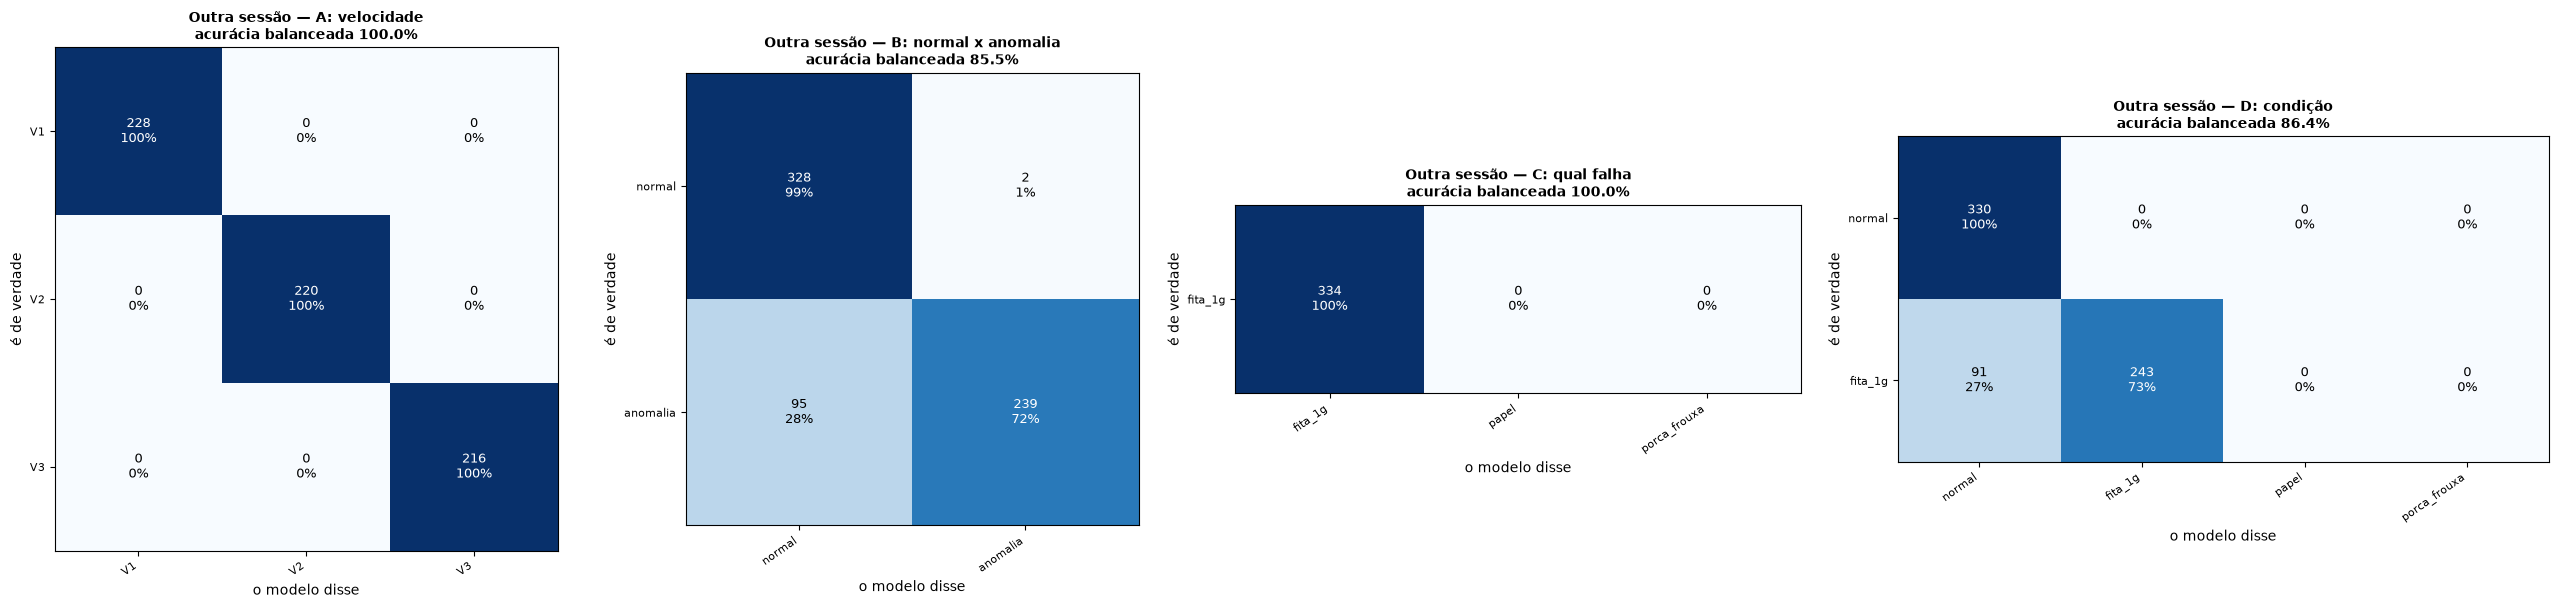

Tarefa B na outra sessão — % chamada de anomalia (linha do normal = falso alarme):


velocidade,V1,V2,V3
condicao,,,
normal,0.0,0.0,2.0
fita_1g,13.6,100.0,100.0


Tarefa D na outra sessão — para onde foi cada condição e velocidade (% da linha):


o modelo disse                     normal  fita_1g  papel  porca_frouxa
rotulo_condicao rotulo_velocidade                                      
fita_1g         V1                   82.7     17.3      0             0
                V2                    0.0    100.0      0             0
                V3                    0.0    100.0      0             0
normal          V1                  100.0      0.0      0             0
                V2                  100.0      0.0      0             0
                V3                  100.0      0.0      0             0

Rotação mediana (f1x_hz) por velocidade: dados novos × outra sessão


,dados novos (normal),outra sessão (normal)
rotulo_velocidade,,
V1,12.4,12.8
V2,18.6,19.4
V3,22.6,23.6


In [50]:
fig, axs = plt.subplots(1, 4, figsize=(26, 6), gridspec_kw={"width_ratios": [1, 0.8, 1, 1.15]})
for ax, (tarefa, (dados, coluna, classes)) in zip(axs, TAREFAS_OUTRA.items()):
    presentes = [c for c in classes if (dados[coluna] == c).any()]
    plotar_matriz(dados[coluna].to_numpy(), resultados_outra[tarefa], presentes, f"Outra sessão — {tarefa}", ax=ax, classes_previstas=classes)
plt.tight_layout()
plt.show()

print("Tarefa B na outra sessão — % chamada de anomalia (linha do normal = falso alarme):")
display(taxa_de_anomalia_por_condicao(outra_sessao, resultados_outra["B: normal x anomalia"]).round(1))
print("Tarefa D na outra sessão — para onde foi cada condição e velocidade (% da linha):")
destino = pd.crosstab([outra_sessao["rotulo_condicao"], outra_sessao["rotulo_velocidade"]],
                      pd.Series(resultados_outra["D: condição"], name="o modelo disse", index=outra_sessao.index), normalize="index")
display((100 * destino).reindex(columns=ORDEM_CONDICOES, fill_value=0).round(1))
print("Rotação mediana (f1x_hz) por velocidade: dados novos × outra sessão")
display(pd.DataFrame({"dados novos (normal)": features[features["rotulo_condicao"] == NOME_NORMAL].groupby("rotulo_velocidade")["f1x_hz"].median(),
                      "outra sessão (normal)": outra_sessao[outra_sessao["rotulo_condicao"] == NOME_NORMAL].groupby("rotulo_velocidade")["f1x_hz"].median()}).round(2))

### Resultado do teste em outra sessão (dados novos → dados antigos)

| Tarefa | Mesma sessão (trancado) | **Outra sessão** | Pior recall na outra sessão |
| --- | --- | --- | --- |
| A: velocidade | 100% | **100%** | 100% |
| B: normal × anomalia | 99,5% | **85,5%** | 71,6% |
| C: qual falha (só fita) | 99,1% | **100%** | 100% |
| D: condição | 99,1% | **86,4%** | 72,8% |

* **Velocidade: 100% em outra sessão.** A rotação dos dados antigos é um pouco maior (normal 12,8 / 19,4 / 23,6 Hz contra 12,4 / 18,6 / 22,6 Hz nos novos), mas continua dentro da faixa certa.
* **Falso alarme em outra sessão: 0%, 0% e 2%.** O normal antigo foi reconhecido como normal. **Esse é o resultado mais importante deste notebook:** o modelo não confundiu "outro dia" com "falha".
* **Fita V2 e V3: 100% detectadas** e classificadas como fita, mesmo em outra sessão.
* **Fita V1: só 13,6% detectada.** Na Tarefa D, 82,7% das janelas foram chamadas de normal. A fita mais fraca (Vel 1) **não sobreviveu à troca de sessão**. Ela já era o caso frágil em todos os notebooks: nos dados antigos (K=2 global com 0%), no K-Means dos dados novos e nos erros do trancado.
* **Diagnóstico (C): 100% das janelas de fita antigas foram chamadas de fita**, inclusive as da Vel 1. Ou seja, **quando a janela chega ao diagnóstico, ele reconhece a fita**. Quem falha é o **detector**: o limite dele não acusa a fita V1 antiga.
* **Leitura honesta:** a queda de 99% para cerca de 86% vem toda de **uma classe** (fita V1). Não é um colapso geral, mas mostra que **falhas fracas dependem da sessão**. Com uma única sessão de treino, o detector aprende o limite "desta" fita V1. Em outro dia, com montagem ou temperatura diferentes, a fita V1 ficou do lado normal do limite.
* **Nenhum ajuste foi feito depois de ver este resultado.**

## Resumo e decisões

**O que buscamos:** levar para o Notebook 05b e para o modelo final o que este notebook mostrou.

### Decisões e o que levar adiante (dados novos)

**Respostas do notebook:**

1. **Velocidade:** 100% no trancado e **100% em outra sessão**, com uma feature só (`f1x_hz`).
2. **Detecção (normal × anomalia):**
   * 99,5% no trancado, com **0% de falso alarme** e a **porca V2 a 100%**;
   * em outra sessão, 0% a 2% de falso alarme, mas **a fita V1 antiga passou quase toda**.
3. **Diagnóstico (qual falha):** 99,1% no trancado. Em outra sessão, todas as fitas antigas foram reconhecidas como fita.
4. **Condição (4 classes):** 99,1% no trancado com a arquitetura **detector → tipo**, que empatou ou superou as outras duas.

**Decisões:**

| Decisão | Por quê |
| --- | --- |
| **Arquitetura final: detector → tipo** ("um modelo chama o outro") | Melhor acurácia balanceada e melhor pior recall na Tarefa D. É modular: dá para trocar o diagnóstico quando entrar uma falha nova. |
| **Etapa de velocidade, quando necessária: só `f1x_hz`** | 100% no trancado, em outra sessão e na divisão cronológica, sem depender da falha nem do aquecimento. |
| **Regressão logística** em todas as etapas | Ganhou ou empatou em todas as tarefas; é o modelo mais simples e interpretável. |
| **Treino com o motor frio e o quente** | O teste cronológico mostrou que um modelo treinado num só estado térmico erra no outro (normal V2 quente acusado, porca V2 fria perdida). |
| **Regra de escolha com desempate pelo pior recall** | Na Tarefa D, ela evitou trocar o pior recall de 99,2% por 98,4% só para usar menos features. |

**Ressalvas para o texto do TCC:**

* **Dentro da sessão, os números estão perto de 100%**, mas isso vale para trechos diferentes **da mesma gravação**.
* **Em outra sessão, a falha fraca (fita V1) não foi detectada.** É o principal limite do trabalho até aqui, e precisa aparecer no texto.
* **Os erros que restam estão todos nos primeiros segundos ou minutos depois de ligar o motor**, com a fita ainda "fraca".
* **O teste trancado e o teste em outra sessão já foram abertos.** Mudanças de método daqui em diante só podem ser avaliadas em dados novos.

**Próximos passos:**
1. **Notebook 06:** o detector treinado **só com o normal**, com os mesmos blocos e o mesmo trancado. Ele responde se dá para detectar sem nunca ter visto a falha, e se a fita V1 da outra sessão seria acusada por fugir do normal.
2. **Nova sessão de gravação:** pelo menos o normal e a fita V1, em outro dia e, de preferência, também com o motor já aquecido. É o que falta para saber se a fita V1 é detectável entre sessões.
3. **Engenharia de features (depois do 06):** features que não mudem com o aquecimento nem com a sessão (faixas presas à rotação, razões entre faixas), com este notebook como referência.

## O que conferir antes de seguir para o Notebook 06

* [ ] **Passos 3 e 4:** você entendeu por que blocos, por que guarda e por que um bloco trancado em cada terço da gravação.
* [ ] **Passo 5:** você entendeu por que o trancado não aparece em nenhuma rodada da validação.
* [ ] **Passo 6:** o scaler é ajustado só no treino (pipeline), e as três arquiteturas estão claras.
* [ ] **Passo 7:** a regra de escolha foi escrita **antes** dos resultados (inclui o pior recall no desempate).
* [ ] **Passos 8 a 11:** os modelos escolhidos e as comparações (features, arquiteturas) estão anotados, com a porca V2 em destaque.
* [ ] **Passo 12:** os testes anti-ilusão, principalmente a **divisão cronológica nos dois sentidos**, foram lidos.
* [ ] **Passo 13:** o número do teste trancado está anotado **e nada foi mudado depois de vê-lo**.
* [ ] **Passo 14:** o resultado em outra sessão está anotado, com a explicação de qualquer queda.

**Próximo passo:** Notebook 06, o **detector treinado só com o ventilador saudável**, com os mesmos blocos e o mesmo teste trancado.